(sec-4)=
# 4. Implementación de los modelos del benchmark

En esta sección se implementan los 13 modelos profundos y las tres líneas base no profundas bajo el mismo entorno, el mismo pipeline y el mismo presupuesto de ajuste, siguiendo la ruta F1 del enunciado y el protocolo de su sección 11. El orden es el del enunciado: diseño experimental (4.1), implementación y ajuste (4.2), requisitos experimentales, con el piloto, la potencia y la búsqueda de arquitectura (4.3), buenas prácticas contra la fuga (4.4), evaluación (4.5) y robustez, interpretabilidad y ablación (4.6).

(sec-4-1)=
## 4.1 Diseño experimental

| Elemento | Definición |
|---|---|
| Variables de entrada | Los 16 atributos de tráfico y desempeño, recortados, transformados con $\log(1 + x)$ y estandarizados con entrenamiento (sección {ref}`2.2.1 <sec-2-2-1>`) |
| Variable objetivo y tarea | Una de las 5 clases; clasificación multiclase de cada flujo, sin horizonte ni rezagos |
| División del dataset | Entrenamiento, validación y prueba heredados del Entregable 1 (64, 16 y 20 %), estratificados por clase y agrupados por bloques, idénticos para todos los modelos; la prueba se toca una sola vez por corrida |
| Pipeline | Un único pipeline por modelo, en `codigo/`: datos y transformación (`datos.py`), modelos (`modelos.py`), entrenamiento (`motor.py`), líneas base (`clasicos.py`) y ejecución en paralelo con reanudación (`ejecutor.py`) |
| Selección de hiperparámetros | Búsqueda aleatoria con las mismas 12 configuraciones para los 13 modelos profundos, 15 épocas y una semilla, elegida solo con el F1 macro de validación; LightGBM y la regresión logística reciben 12 configuraciones de su propio espacio |
| Arquitectura no predefinida | Búsqueda de la sección 14 para ResNet, Autoencoder, DBN y CNN-LSTM: 1000 arquitecturas en la fase 1 y k finalistas con 5 semillas en la fase 2 |
| Repeticiones | R semillas por modelo, con R fijado por el piloto (sección {ref}`4.3 <sec-4-3>`) y las mismas semillas para todos |
| Validación interna | Partición fija de validación para seleccionar, más una validación cruzada 5 × 2 agrupada por bloques sobre entrenamiento + validación para las pruebas de Nadeau y Bengio y de Alpaydin en el contraste de RQ2 |
| Evaluación | Mismas métricas sobre la misma prueba (sección {ref}`4.5 <sec-4-5>`) |

La validación anidada completa, que repetiría el ajuste dentro de cada pliegue externo, multiplicaría por 12 el costo de todo el benchmark, de modo que se reemplaza por la comparación entre el puntaje de validación usado para seleccionar y el de prueba (tabla B, sección 7), que mide el mismo optimismo por selección.

(sec-4-2)=
## 4.2 Implementación de los modelos

Todos los modelos profundos se implementan en PyTorch y se entrenan con Adam (Kingma y Ba, 2015), con la versión de la configuración del entorno; TabNet usa la red de la implementación de referencia pytorch-tabnet y los demás, capas estándar de PyTorch. Ningún modelo usa pesos preentrenados, de modo que no aplica la comparación con y sin preentrenamiento ni la fuga por modelos preentrenados. Las líneas base usan scikit-learn y LightGBM.

Hay una corrección respecto del Entregable 1: los tres modelos base usan ahora el *dropout* exacto del código de los autores (Zeng, 2025), que el Entregable 1 declaró como desviación y evaluó con un análisis de sensibilidad.

In [35]:
FUENTE = {"DNN": "Zeng (2025)", "CNN 1D": "Zeng (2025)", "LSTM": "Zeng (2025)", "RNN": "Biswas et al. (2026)", "GRU": "Biswas et al. (2026)", "BiLSTM": "Balgoon (2026)",
          "Transformer": "Biswas et al. (2026), TSLT-Net", "TabNet": "Arik y Pfister (2021); pytorch-tabnet 4.1.0", "KAN": "Bakiri et al. (2026)", "ResNet": "Búsqueda (sección 4.3)",
          "Autoencoder": "Búsqueda (sección 4.3)", "DBN": "Búsqueda (sección 4.3)", "CNN-LSTM": "Búsqueda (sección 4.3)"}
ADAPTACION = {"DNN": "Ninguna", "CNN 1D": "Ninguna", "LSTM": "Ninguna", "RNN": "Ninguna; la secuencia es la de las 16 columnas", "GRU": "Ninguna; la secuencia es la de las 16 columnas",
              "BiLSTM": "Cabeza lineal sobre los dos últimos estados, que el artículo no detalla", "Transformer": "PyTorch MultiheadAttention en lugar de Keras", "TabNet": "Entrenado con el motor común",
              "KAN": "Clasificador de 5 clases en lugar de 4 ataques", "ResNet": "Bloque residual denso", "Autoencoder": "Supervisado, λ = 1", "DBN": "CD-1, 3 épocas por RBM",
              "CNN-LSTM": "Correspondencia aproximada de 3 bloques"}
fuera_rango = float((np.abs(H["X"][ID_ENT]) > 5).mean())
tabla(complejidad_modelos.assign(Fuente=complejidad_modelos["Modelo"].map(FUENTE), Adaptación=complejidad_modelos["Modelo"].map(ADAPTACION))[["Modelo", "Familia", "Fuente", "Adaptación", "Parámetros", "FLOPs por muestra"]],
      {"Parámetros": "{:,.0f}", "FLOPs por muestra": "{:,.0f}"})
print(f"Valores estandarizados de entrenamiento fuera de [-5, 5], que la KAN recorta: {num(100 * fuera_rango, 2)} %")

Modelo,Familia,Fuente,Adaptación,Parámetros,FLOPs por muestra
DNN,Perceptrón multicapa,Zeng (2025),Ninguna,12 677,24 896
CNN 1D,Convolucional,Zeng (2025),Ninguna,39 493,265 856
LSTM,Recurrente,Zeng (2025),Ninguna,17 477,533 120
CNN-LSTM,Híbrida,Búsqueda (sección 4.3),Correspondencia aproximada de 3 bloques,46 213,924 288
Autoencoder,Codificador-decodificador,Búsqueda (sección 4.3),"Supervisado, λ = 1",19 093,19 072
RNN,Recurrente,Biswas et al. (2026),Ninguna; la secuencia es la de las 16 columnas,38 277,939 264
Transformer,Atención,"Biswas et al. (2026), TSLT-Net",PyTorch MultiheadAttention en lugar de Keras,3 381,22 144
BiLSTM,Recurrente,Balgoon (2026),"Cabeza lineal sobre los dos últimos estados, que el artículo no detalla",530 693,16 812 544
ResNet,Residual,Búsqueda (sección 4.3),Bloque residual denso,24 005,45 696
GRU,Recurrente,Biswas et al. (2026),Ninguna; la secuencia es la de las 16 columnas,96 901,2 782 464


Valores estandarizados de entrenamiento fuera de [-5, 5], que la KAN recorta: 0,14 %


(sec-4-2-1)=
### 4.2.1 Ajuste de hiperparámetros con el mismo presupuesto

Cada modelo profundo recibe las mismas 12 configuraciones de tasa de aprendizaje, *weight decay* y tamaño de lote, muestreadas con semilla 2026 de la rejilla del preregistro, con una semilla de entrenamiento y un máximo de 15 épocas. Los modelos con búsqueda de arquitectura se ajustan con la arquitectura de referencia (64, 64, 64) y *dropout* (0, 1, 0), como pide la sección 14.3, de modo que la búsqueda posterior solo cambia los anchos y el *dropout*. Los demás hiperparámetros de cada arquitectura, como el *dropout* de los modelos definidos, quedan en los valores de su fuente.

Configuración,DNN,CNN 1D,LSTM,CNN-LSTM,Autoencoder,RNN,Transformer,BiLSTM,ResNet,GRU,KAN,TabNet,DBN
"0: lr 10⁻⁴, wd 10⁻⁴, lote 256","0,9119","0,9229","0,7962","0,9261","0,9106","0,9278","0,9186","0,8452","0,9230","0,9140","0,9116","0,8158","0,6765"
"1: lr 10⁻³, wd 0, lote 512","0,9303","0,9334","0,8758","0,9231","0,9260","0,9265","0,9279","0,8814","0,9190","0,9270","0,9161","0,9088","0,8958"
"2: lr 3 × 10⁻³, wd 10⁻⁵, lote 512","0,9293","0,9288","0,8959","0,9295","0,9242","0,9280","0,9289","0,9036","0,9239","0,9214","0,9245","0,9112","0,9184"
"3: lr 3 × 10⁻³, wd 10⁻⁴, lote 128","0,9307","0,9289","0,9144","0,9235","0,9270","0,9212","0,9267","0,9119","0,9252","0,9187","0,9302","0,9156","0,9200"
"4: lr 10⁻⁴, wd 10⁻⁴, lote 128","0,9183","0,9281","0,8377","0,9287","0,9194","0,9286","0,9140","0,8614","0,9264","0,9283","0,9177","0,8670","0,7812"
"5: lr 3 × 10⁻³, wd 0, lote 256","0,9263","0,9221","0,9151","0,9336","0,9283","0,9266","0,9049","0,9069","0,9245","0,9257","0,9276","0,9135","0,9259"
"6: lr 3 × 10⁻³, wd 10⁻⁴, lote 512","0,9296","0,9286","0,8924","0,9292","0,9252","0,9313","0,9263","0,9169","0,9225","0,9249","0,9256","0,9207","0,9140"
"7: lr 3 × 10⁻³, wd 10⁻⁵, lote 128","0,9287","0,9302","0,9212","0,9240","0,9279","0,9201","0,9212","0,9209","0,9257","0,9188","0,9328","0,8999","0,9281"
"8: lr 10⁻³, wd 0, lote 256","0,9317","0,9310","0,8809","0,9304","0,9272","0,9249","0,9256","0,8815","0,9280","0,9297","0,9276","0,9136","0,9116"
"9: lr 3 × 10⁻³, wd 0, lote 128","0,9293","0,9275","0,9199","0,9226","0,9281","0,9031","0,9281","0,8980","0,9257","0,9257","0,9332","0,9146","0,9304"


Modelo,Mejor F1 de validación,Peor,Rango,Configuración elegida,Minutos del ajuste,Divergentes
DNN,"0,9317","0,9119","0,0198","lr 10⁻³, wd 0, lote 256","6,3",0
CNN 1D,"0,9334","0,9221","0,0113","lr 10⁻³, wd 0, lote 512","23,1",0
LSTM,"0,9212","0,7962","0,1250","lr 3 × 10⁻³, wd 10⁻⁵, lote 128","40,1",0
CNN-LSTM,"0,9336","0,9226","0,0109","lr 3 × 10⁻³, wd 0, lote 256","47,7",0
Autoencoder,"0,9283","0,9106","0,0177","lr 3 × 10⁻³, wd 0, lote 256","9,6",0
RNN,"0,9313","0,9031","0,0282","lr 3 × 10⁻³, wd 10⁻⁴, lote 512","157,6",0
Transformer,"0,9289","0,9049","0,0240","lr 3 × 10⁻³, wd 10⁻⁵, lote 512","13,5",0
BiLSTM,"0,9209","0,8452","0,0758","lr 3 × 10⁻³, wd 10⁻⁵, lote 128","608,1",0
ResNet,"0,9280","0,9190","0,0090","lr 10⁻³, wd 0, lote 256","14,6",0
GRU,"0,9297","0,9140","0,0157","lr 10⁻³, wd 0, lote 256","228,6",0


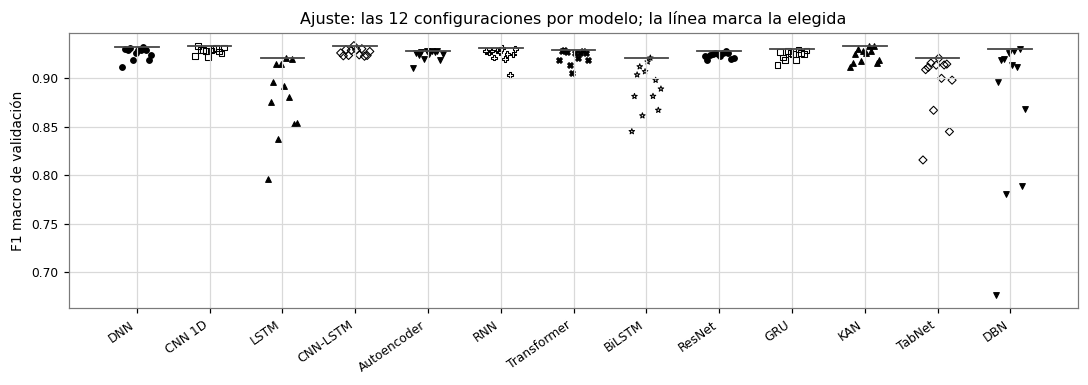

**Interpretación.** El modelo más sensible a los hiperparámetros es DBN, con un rango de 0,2539 en F1 macro de validación entre sus 12 configuraciones, y el menos sensible es ResNet, con 0,0090. Entre los profundos, la tasa de aprendizaje más elegida es 3 × 10⁻³ (9 de 13 modelos) y el lote más elegido, 256 (5 de 13). Ninguna configuración divergió.

Esto significa que el mismo presupuesto no produce el mismo beneficio en todos los modelos: los que tienen un rango amplio dependen más de acertar la configuración, de modo que con un presupuesto menor habrían quedado subestimados, y por eso se iguala el número de intentos y no el tiempo. Hay que tener en cuenta que el ajuste usa una sola semilla, de modo que diferencias entre configuraciones del orden del ruido por semilla, que mide el piloto, no son significativas.

Por tal motivo, se fijan para la ejecución definitiva las configuraciones de la tabla, elegidas solo con validación, y el resto del protocolo queda congelado.

In [36]:
from codigo import resultados as RES
from codigo import plan as PLAN

ajuste = RES.tabla_fase("ajuste")
PROFUNDOS = CONFIG["modelos"]["base_e1"] + CONFIG["modelos"]["top10"]
configs = PLAN.configuraciones_ajuste()["profundos"]
def cientifico(x):
    # 0,0003 se escribe 3 × 10⁻⁴, para no mezclar el punto decimal con la coma de las tablas
    if x == 0:
        return "0"
    if 0.01 <= abs(x) < 1e4:
        return f"{x:.4g}".replace(".", ",")
    e = int(np.floor(np.log10(abs(x))))
    m = round(x / 10 ** e, 3)
    sup = str(e).translate(str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹"))
    return f"10{sup}" if m == 1 else f"{num(m, 0) if m == int(m) else num(m, 1)} × 10{sup}"
etiqueta_cfg = [f"{i}: lr {cientifico(c['lr'])}, wd {cientifico(c['weight_decay'])}, lote {c['batch']}" for i, c in enumerate(configs)]
pivote = ajuste[ajuste["modelo"].isin(PROFUNDOS)].pivot(index="intento", columns="modelo", values="f1_val")[PROFUNDOS]
pivote.index = etiqueta_cfg
tabla(pivote.reset_index(names="Configuración"), {m: "{:.4f}" for m in PROFUNDOS})
MEJORES_HP = PLAN.mejores_hp()
NOMBRE_HP = {"weight_decay": "wd", "batch": "lote"}
resumen_ajuste = pd.DataFrame([{"Modelo": m, "Mejor F1 de validación": ajuste.loc[ajuste["modelo"] == m, "f1_val"].max(), "Peor": ajuste.loc[ajuste["modelo"] == m, "f1_val"].min(),
                                "Rango": ajuste.loc[ajuste["modelo"] == m, "f1_val"].max() - ajuste.loc[ajuste["modelo"] == m, "f1_val"].min(),
                                "Configuración elegida": ", ".join(f"{NOMBRE_HP.get(k, k)} {cientifico(v)}" if isinstance(v, float) else f"{NOMBRE_HP.get(k, k)} {v}" for k, v in MEJORES_HP[m].items()),
                                "Minutos del ajuste": ajuste.loc[ajuste["modelo"] == m, "segundos"].sum() / 60, "Divergentes": int(ajuste.loc[ajuste["modelo"] == m, "divergente"].sum())}
                               for m in PROFUNDOS + ["LightGBM", "Logística"]])
tabla(resumen_ajuste, {"Mejor F1 de validación": "{:.4f}", "Peor": "{:.4f}", "Rango": "{:.4f}", "Minutos del ajuste": "{:.1f}"})
fig, eje = plt.subplots(figsize=(10, 3.6))
for j, m in enumerate(PROFUNDOS):
    v = pivote[m].to_numpy()
    eje.scatter(np.full(len(v), j) + np.linspace(-0.2, 0.2, len(v)), v, s=14, marker=MARCADORES[j % len(MARCADORES)], facecolors="none" if j % 2 else NEGRO, edgecolors=NEGRO, lw=0.7)
    eje.plot([j - 0.3, j + 0.3], [v.max()] * 2, color=GRIS_OSCURO, lw=1.2)
eje.set_xticks(range(len(PROFUNDOS)), PROFUNDOS, rotation=35, ha="right")
eje.set_ylabel("F1 macro de validación")
eje.set_title("Ajuste: las 12 configuraciones por modelo; la línea marca la elegida")
plt.tight_layout()
plt.show()
mas_sensible = resumen_ajuste.loc[resumen_ajuste["Rango"].idxmax()]
menos_sensible = resumen_ajuste.loc[resumen_ajuste.loc[resumen_ajuste["Modelo"].isin(PROFUNDOS), "Rango"].idxmin()]
lote_elegido = pd.Series({m: MEJORES_HP[m]["batch"] for m in PROFUNDOS}).value_counts()
tasa_elegida = pd.Series({m: MEJORES_HP[m]["lr"] for m in PROFUNDOS}).value_counts()
interpretar(f'''**Interpretación.** El modelo más sensible a los hiperparámetros es {mas_sensible["Modelo"]}, con un rango de {num(mas_sensible["Rango"], 4)} en F1 macro de validación entre sus 12 configuraciones, y el menos sensible es {menos_sensible["Modelo"]}, con {num(menos_sensible["Rango"], 4)}. Entre los profundos, la tasa de aprendizaje más elegida es {cientifico(tasa_elegida.index[0])} ({tasa_elegida.iloc[0]} de 13 modelos) y el lote más elegido, {lote_elegido.index[0]} ({lote_elegido.iloc[0]} de 13). {"Ninguna configuración divergió." if resumen_ajuste["Divergentes"].sum() == 0 else f"Divergieron {int(resumen_ajuste['Divergentes'].sum())} configuraciones, que se reportan y no se usan."}

Esto significa que el mismo presupuesto no produce el mismo beneficio en todos los modelos: los que tienen un rango amplio dependen más de acertar la configuración, de modo que con un presupuesto menor habrían quedado subestimados, y por eso se iguala el número de intentos y no el tiempo. Hay que tener en cuenta que el ajuste usa una sola semilla, de modo que diferencias entre configuraciones del orden del ruido por semilla, que mide el piloto, no son significativas.

Por tal motivo, se fijan para la ejecución definitiva las configuraciones de la tabla, elegidas solo con validación, y el resto del protocolo queda congelado.''')

**Hiperparámetros y estrategia de entrenamiento.** La tabla reúne lo que pide la sección 4.2 del enunciado para cada modelo. Todo el entrenamiento es en precisión simple (float32) en CPU, sin precisión mixta, porque no hay GPU.

In [37]:
DROPOUT = {"DNN": "0,2 tras las capas de 128 y 64", "CNN 1D": "0,2 antes de la densa", "LSTM": "0,2 antes de la salida", "RNN": "0,3", "GRU": "0,3 en tres posiciones", "BiLSTM": "0,3",
           "Transformer": "0,3 antes de la salida", "TabNet": "No usa; regularización de dispersión λ = 10⁻³", "KAN": "0,25 y 0,20", "ResNet": "Por búsqueda", "Autoencoder": "Por búsqueda",
           "DBN": "Por búsqueda", "CNN-LSTM": "Por búsqueda"}
hp_tabla = pd.DataFrame([{"Modelo": m, "Optimizador": "Adam", "Tasa de aprendizaje": cientifico(MEJORES_HP[m]["lr"]), "Planificador": "ReduceLROnPlateau (0,1; 2)", "Weight decay": cientifico(MEJORES_HP[m]["weight_decay"]),
                          "Lote": MEJORES_HP[m]["batch"], "Dropout": DROPOUT[m], "Pérdida": "CE ponderada" + (" + dispersión" if m == "TabNet" else " + reconstrucción" if m == "Autoencoder" else ""),
                          "Épocas máximas": CONFIG["entrenamiento"]["max_epocas"], "Parada temprana": f"Paciencia {CONFIG['entrenamiento']['paciencia']} sobre F1 de validación",
                          "Recorte de gradiente": f"Norma {CONFIG['entrenamiento']['norma_gradiente']:g}"} for m in PROFUNDOS])
tabla(hp_tabla, {})

Modelo,Optimizador,Tasa de aprendizaje,Planificador,Weight decay,Lote,Dropout,Pérdida,Épocas máximas,Parada temprana,Recorte de gradiente
DNN,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,"0,2 tras las capas de 128 y 64",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
CNN 1D,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,512,"0,2 antes de la densa",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
LSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,128,"0,2 antes de la salida",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
CNN-LSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
Autoencoder,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada + reconstrucción,30,Paciencia 6 sobre F1 de validación,Norma 5
RNN,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁴,512,"0,3",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
Transformer,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,512,"0,3 antes de la salida",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
BiLSTM,Adam,3 × 10⁻³,"ReduceLROnPlateau (0,1; 2)",10⁻⁵,128,"0,3",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
ResNet,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,Por búsqueda,CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5
GRU,Adam,10⁻³,"ReduceLROnPlateau (0,1; 2)",0,256,"0,3 en tres posiciones",CE ponderada,30,Paciencia 6 sobre F1 de validación,Norma 5


(sec-4-3)=
## 4.3 Requisitos experimentales

**Semillas y determinismo.** Cada corrida fija las semillas de Python, NumPy y PyTorch, y el orden de los lotes sale de un generador con la misma semilla; las operaciones de PyTorch en CPU que se usan son deterministas con un número de hilos fijo, de modo que una corrida se puede repetir con la misma semilla. No se activa `torch.use_deterministic_algorithms`, porque no hay GPU. Las semillas son 4242 para el ajuste, 4101 a 4105 para el piloto, 5000 para la fase 1, 5101 a 5105 para la fase 2, 5201 a 5203 para el ruido por semilla y desde 6001 para la ejecución definitiva.

**Seguimiento de experimentos.** El ejecutor guarda cada corrida en un JSON con su configuración, semilla, curvas por época, tiempo, memoria, equipo y métricas, y la configuración del experimento está versionada en `configuracion/experimento.json`. Ese registro por corrida cumple la función de una herramienta de seguimiento como MLflow sin agregar una dependencia, y se consolida en `entregables/registro_experimentos.csv`.

**Cómputo.** Todo corre en CPU, de modo que no hay ventaja de GPU para ningún modelo; los trabajos se reparten entre procesos de 2 hilos y cada modelo recibe el mismo número de intentos, no el mismo tiempo.

**Preregistro, desviaciones y aclaraciones.** El preregistro (`preregistro_e2.md`) quedó fechado y versionado el 12 de noviembre de 2026 a las 13:12, con la etiqueta `preregistro-e2`, antes del primer entrenamiento. La adenda (`preregistro_e2_adenda.md` y `resultados/preregistro_e2_adenda.json`) registra con fecha las cifras que dependían del piloto y de la búsqueda, y tres cambios declarados antes de usarlos: la **desviación 1**, que entrena la fase 1 de la búsqueda y el estudio de ruido con un subconjunto fijo del 25 % de los bloques de entrenamiento (20 bloques, 19 351 flujos), porque el protocolo completo medía unas 40 horas de cómputo; la **aclaración 1**, que limita la validación cruzada 5 × 2 al contraste de RQ2, el único que la usa, y la **aclaración 2**, que promedia el F1 macro de cada bloque de prueba sobre las clases presentes en él. Ninguna se decidió después de ver resultados de prueba.

(sec-4-3-1)=
### 4.3.1 Estudio piloto y número de ejecuciones

El piloto entrena cuatro modelos representativos, el baseline del Entregable 1 (CNN 1D) y tres del Top 10 de familias distintas (Transformer, RNN y KAN), con cinco semillas y sobre validación, para estimar la desviación de las diferencias pareadas frente al baseline y fijar R con la regla del preregistro. El mismo piloto verifica la limitación del paper guía en tres modelos del Top 10 (sección 5).

In [38]:
ADENDA = json.loads((RESULTADOS / "preregistro_e2_adenda.json").read_text(encoding="utf-8"))
pil = ADENDA["piloto"]
tabla(pd.DataFrame(pil["f1_validacion"]).rename_axis("Semilla").reset_index(), {m: "{:.4f}" for m in pil["f1_validacion"]})
tabla(pd.DataFrame([{"Par": p, "Diferencia media": v["media"], "σ̂_d": v["sigma_d"], "Shapiro-Wilk, p": v["shapiro_p"]} for p, v in pil["pares_frente_al_baseline"].items()]),
      {"Diferencia media": "{:.4f}", "σ̂_d": "{:.4f}", "Shapiro-Wilk, p": "{:.3f}"})
R = ADENDA["R"]
SEMILLAS = [CONFIG["definitiva"]["semilla_inicial"] + i for i in range(R)]
interpretar(f'''**Interpretación.** En el piloto, la mayor desviación de las diferencias pareadas frente a CNN 1D es σ̂_d = {num(pil["sigma_piloto"], 4)}, y la regla del preregistro toma el máximo entre ella y la del Entregable 1 en prueba, {num(pil["sigma_e1_prueba"], 4)}, de modo que se usa σ̂_d = {num(pil["sigma_usada"], 4)}. Con α′ = 0,05/10 y potencia de 0,80, detectar δ exigiría R = {pil["R_calculado"]} ejecuciones; {"el tope de cómputo es " + str(CONFIG["definitiva"]["R_tope"]) + ", de modo que se usa R = " + str(R) if pil["limitado_por_tope"] else "se usa R = " + str(R)}, con una diferencia mínima detectable de {num(pil["diferencia_minima_detectable"], 4)} en cada contraste de RQ1.

Esto significa que, {"como en el Entregable 1, el diseño no alcanza a detectar con potencia de 0,80 una diferencia de magnitud δ tras la corrección de Bonferroni, y que solo diferencias de unas " + num(pil["diferencia_minima_detectable"] / DELTA, 1) + " veces δ quedarían detectadas" if pil["limitado_por_tope"] else "el diseño detecta δ con la potencia deseada"}. Hay que tener en cuenta que la cifra es conservadora, porque Holm es menos exigente que Bonferroni salvo en el primer contraste.

Por lo anterior, conviene declarar la diferencia mínima detectable como limitación y leer los resultados no significativos con TOST y con la prueba bayesiana, y no como ausencia de diferencias. Las semillas definitivas son {SEMILLAS[0]} a {SEMILLAS[-1]}, las mismas para los 15 modelos entrenables (el trivial es determinista y usa solo la primera), y quedaron fijadas en la adenda del preregistro el {pil["fecha"]}.''')

Semilla,CNN 1D,KAN,RNN,Transformer
4101,"0,9295","0,9297","0,9102","0,9298"
4102,"0,9320","0,9268","0,9222","0,9211"
4103,"0,9296","0,9311","0,9199","0,9229"
4104,"0,9243","0,9177","0,9094","0,9308"
4105,"0,9263","0,9295","0,9257","0,9195"


Par,Diferencia media,σ̂_d,"Shapiro-Wilk, p"
KAN - CNN 1D,"-0,0014","0,0043","0,385"
RNN - CNN 1D,"-0,0109","0,0070","0,793"
Transformer - CNN 1D,"-0,0035","0,0069","0,576"


**Interpretación.** En el piloto, la mayor desviación de las diferencias pareadas frente a CNN 1D es σ̂_d = 0,0070, y la regla del preregistro toma el máximo entre ella y la del Entregable 1 en prueba, 0,0177, de modo que se usa σ̂_d = 0,0177. Con α′ = 0,05/10 y potencia de 0,80, detectar δ exigiría R = 42 ejecuciones; el tope de cómputo es 20, de modo que se usa R = 20, con una diferencia mínima detectable de 0,0162 en cada contraste de RQ1.

Esto significa que, como en el Entregable 1, el diseño no alcanza a detectar con potencia de 0,80 una diferencia de magnitud δ tras la corrección de Bonferroni, y que solo diferencias de unas 1,6 veces δ quedarían detectadas. Hay que tener en cuenta que la cifra es conservadora, porque Holm es menos exigente que Bonferroni salvo en el primer contraste.

Por lo anterior, conviene declarar la diferencia mínima detectable como limitación y leer los resultados no significativos con TOST y con la prueba bayesiana, y no como ausencia de diferencias. Las semillas definitivas son 6001 a 6020, las mismas para los 15 modelos entrenables (el trivial es determinista y usa solo la primera), y quedaron fijadas en la adenda del preregistro el 2026-11-12 16:58.

(sec-4-3-2)=
### 4.3.2 Búsqueda de arquitectura para los modelos sin diseño definido

ResNet, Autoencoder, DBN y CNN-LSTM recorren el espacio de la sección 14: 3 bloques, anchos de {16, 32, 64, 128, 256} en todas las combinaciones y *dropout* de 0,2 tras cada bloque según b ∈ {0, 1}³, es decir, 1000 arquitecturas por modelo, generadas por código e identificadas como `w64-64-64_d010`. Los demás hiperparámetros se fijaron antes con la arquitectura de referencia (sección {ref}`4.2.1 <sec-4-2-1>`). El protocolo es el de dos fases del enunciado, con la desviación 1: la fase 1 y el estudio de ruido entrenan con el 25 % de los bloques de entrenamiento, se mantienen las 1000 arquitecturas, las 6 épocas y la validación completa, y la fase 2 vuelve al entrenamiento completo. Como menos datos hacen más ruidoso el F1 de la fase 1 y pueden favorecer arquitecturas pequeñas, se reporta la correlación de rangos entre las dos fases.

**Ruido por semilla y número de finalistas.** Antes de la fase 1 se entrenan 5 arquitecturas por modelo con 3 semillas a presupuesto de fase 1, para comparar la desviación entre semillas de una misma arquitectura con la desviación entre arquitecturas y fijar k con la regla del preregistro.

In [39]:
ruido = RES.tabla_fase("ruido")
tabla_ruido = ruido.groupby(["modelo", "arquitectura"])["f1_val"].agg(["mean", "std"]).reset_index()
tabla_ruido["arquitectura"] = tabla_ruido["arquitectura"].map(MOD.identificador)
tabla(tabla_ruido.rename(columns={"modelo": "Modelo", "arquitectura": "Arquitectura", "mean": "Media de F1 (3 semillas)", "std": "DE entre semillas"}),
      {"Media de F1 (3 semillas)": "{:.4f}", "DE entre semillas": "{:.4f}"})
rs = ADENDA["ruido_semilla"]
K_FINALISTAS = rs["k"]
interpretar(f'''**Interpretación.** La razón entre la desviación dentro de cada arquitectura (entre semillas) y la desviación entre arquitecturas va de {num(min(rs["razon_dentro_entre"].values()), 2)} en {min(rs["razon_dentro_entre"], key=rs["razon_dentro_entre"].get)} a {num(max(rs["razon_dentro_entre"].values()), 2)} en {max(rs["razon_dentro_entre"], key=rs["razon_dentro_entre"].get)}. Con la regla del preregistro, k = {K_FINALISTAS}.

Lo anterior indica que {"el ruido por semilla es comparable a la dispersión real entre arquitecturas en al menos un modelo, de modo que el orden de la fase 1 es ruidoso y el mejor verdadero puede quedar fuera de los finalistas; según la simulación del enunciado, con un ruido igual a la dispersión, la probabilidad de capturarlo con k = 10 es de cerca del 50 %" if K_FINALISTAS == 20 else "el ruido por semilla es pequeño frente a la dispersión entre arquitecturas, de modo que el orden de la fase 1 es informativo"}.

Por tal motivo, se conservan {K_FINALISTAS} finalistas por modelo, más la referencia (64, 64, 64) con *dropout* (0, 1, 0), y se reporta la correlación de rangos entre fases para medir cuánto informó el cribado.''')

Modelo,Arquitectura,Media de F1 (3 semillas),DE entre semillas
Autoencoder,w16-128-256_d010,"0,9100","0,0002"
Autoencoder,w32-128-32_d011,"0,9078","0,0002"
Autoencoder,w64-16-16_d100,"0,8952","0,0095"
Autoencoder,w128-32-128_d010,"0,9103","0,0013"
Autoencoder,w256-256-32_d010,"0,9111","0,0018"
CNN-LSTM,w16-128-256_d010,"0,9106","0,0064"
CNN-LSTM,w32-128-32_d011,"0,9128","0,0063"
CNN-LSTM,w64-16-16_d100,"0,9087","0,0068"
CNN-LSTM,w128-32-128_d010,"0,9134","0,0054"
CNN-LSTM,w256-256-32_d010,"0,9117","0,0001"


**Interpretación.** La razón entre la desviación dentro de cada arquitectura (entre semillas) y la desviación entre arquitecturas va de 0,47 en DBN a 2,99 en CNN-LSTM. Con la regla del preregistro, k = 20.

Lo anterior indica que el ruido por semilla es comparable a la dispersión real entre arquitecturas en al menos un modelo, de modo que el orden de la fase 1 es ruidoso y el mejor verdadero puede quedar fuera de los finalistas; según la simulación del enunciado, con un ruido igual a la dispersión, la probabilidad de capturarlo con k = 10 es de cerca del 50 %.

Por tal motivo, se conservan 20 finalistas por modelo, más la referencia (64, 64, 64) con *dropout* (0, 1, 0), y se reporta la correlación de rangos entre fases para medir cuánto informó el cribado.

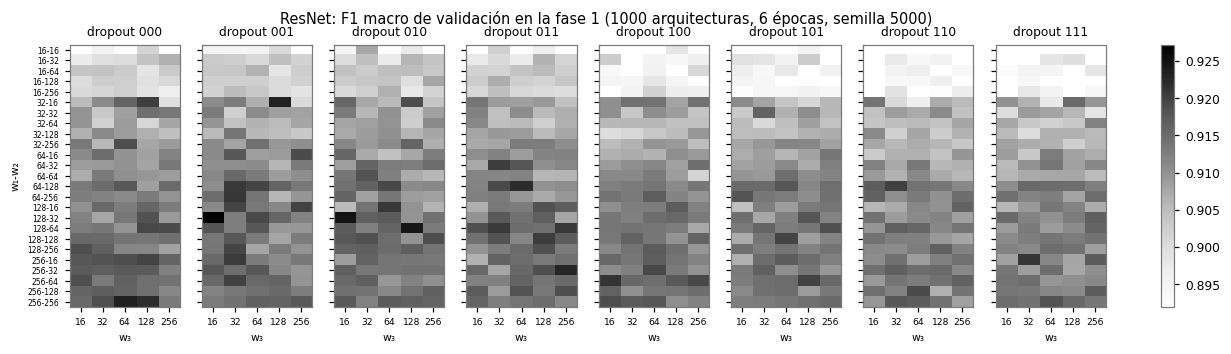

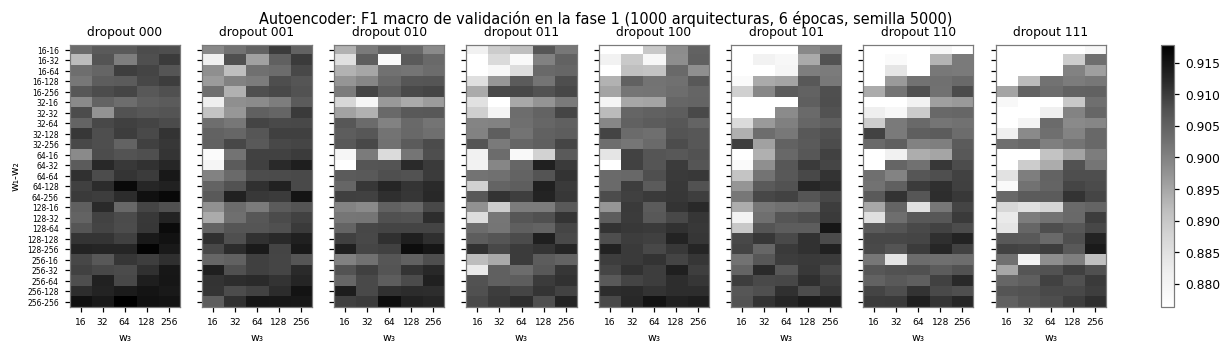

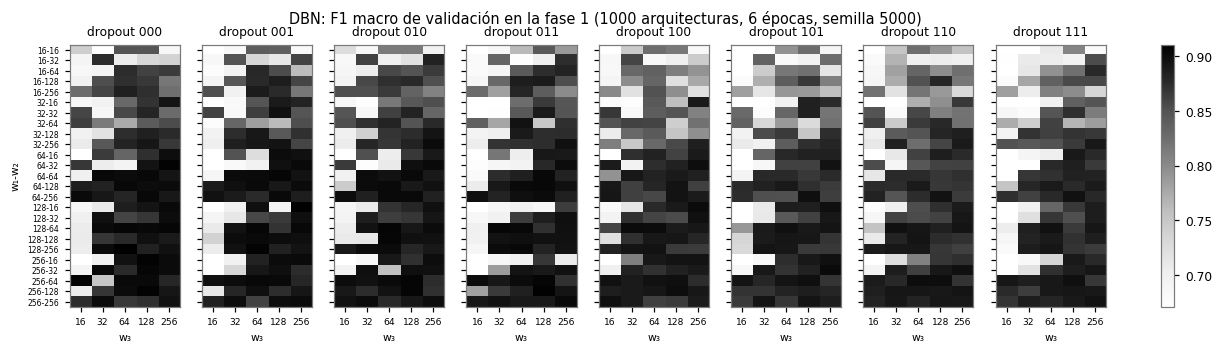

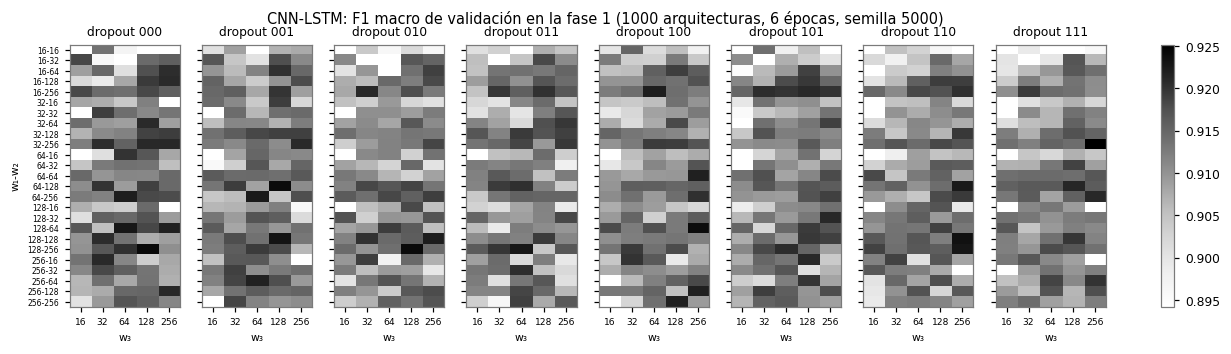

Modelo,min,25%,50%,75%,max,std
Autoencoder,"0,8551","0,9015","0,9065","0,9096","0,9179","0,0109"
CNN-LSTM,"0,8638","0,9066","0,9116","0,9154","0,9252","0,0079"
DBN,"0,4694","0,7441","0,8663","0,8892","0,9107","0,0982"
ResNet,"0,8691","0,9052","0,9103","0,9138","0,9272","0,0081"


In [40]:
f1 = RES.tabla_fase("fase1")
f1[["w1", "w2", "w3", "b1", "b2", "b3"]] = pd.DataFrame(f1["arquitectura"].tolist(), index=f1.index)
f1["patron"] = f1["b1"].astype(str) + f1["b2"].astype(str) + f1["b3"].astype(str)
f1.to_csv(RESULTADOS / "busqueda_fase1.csv", index=False)
CON_BUSQUEDA = CONFIG["modelos"]["con_busqueda"]
for m in CON_BUSQUEDA:
    sub = f1[f1["modelo"] == m]
    fig, ejes = plt.subplots(1, 8, figsize=(13, 3.1), sharey=True)
    lim = (sub["f1_val"].quantile(0.05), sub["f1_val"].max())
    for eje, patron in zip(ejes, sorted(sub["patron"].unique())):
        m_pat = sub[sub["patron"] == patron].pivot_table(index=["w1", "w2"], columns="w3", values="f1_val")
        imagen = eje.imshow(m_pat.to_numpy(), aspect="auto", vmin=lim[0], vmax=lim[1])
        eje.set_title(f"dropout {patron}", fontsize=8)
        eje.set_xticks(range(5), [str(w) for w in MOD.ANCHOS], fontsize=6)
        eje.set_yticks(range(25), [f"{a}-{b}" for a, b in m_pat.index], fontsize=5)
        eje.set_xlabel("w₃", fontsize=7)
        eje.grid(False)
    ejes[0].set_ylabel("w₁-w₂", fontsize=7)
    fig.colorbar(imagen, ax=ejes, fraction=0.015)
    fig.suptitle(f"{m}: F1 macro de validación en la fase 1 (1000 arquitecturas, 6 épocas, semilla 5000)", fontsize=9.5)
    plt.show()
tabla(f1.groupby("modelo")["f1_val"].describe()[["min", "25%", "50%", "75%", "max", "std"]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ["min", "25%", "50%", "75%", "max", "std"]})

**Efectos principales e interacciones.** Sobre las 1000 arquitecturas de cada modelo se ajusta el modelo lineal de la sección 14.6, $y_a = \beta_0 + \sum_{i=1}^{3} \sum_{w \in W} \beta_{i,w} \mathbb{1}[w_i = w] + \sum_i \gamma_i b_i + \sum_{i<j} \lambda_{ij} b_i b_j + \varepsilon_a$, con una ANOVA de tipo II por factor y corrección de Holm por el número de factores, y la proporción de varianza que explica cada uno. Se agregan una prueba de tendencia del ancho, con la regresión sobre $\log_2 w_i$, y la comparación pareada de cada combinación de anchos sin *dropout* frente al promedio de sus siete patrones con *dropout*, con Wilcoxon sobre las 125 combinaciones. Como la fase 1 usa una sola semilla, el error del modelo mezcla el ruido por semilla con el efecto de la arquitectura.

In [41]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests

efectos = []
dropout_pareado = []
for m in CON_BUSQUEDA:
    sub = f1[f1["modelo"] == m].copy()
    ajuste_lm = smf.ols("f1_val ~ C(w1) + C(w2) + C(w3) + b1 + b2 + b3 + b1:b2 + b1:b3 + b2:b3", data=sub).fit()
    anova = anova_lm(ajuste_lm, typ=2)
    ss_total = ((sub["f1_val"] - sub["f1_val"].mean()) ** 2).sum()
    p_holm = multipletests(anova["PR(>F)"].iloc[:-1], method="holm")[1]
    for (factor, fila), ph in zip(anova.iloc[:-1].iterrows(), p_holm):
        efectos.append({"Modelo": m, "Factor": factor.replace("C(", "").replace(")", ""), "F": fila["F"], "p Holm": ph, "% de varianza": 100 * fila["sum_sq"] / ss_total})
    efectos.append({"Modelo": m, "Factor": "Residuo", "F": np.nan, "p Holm": np.nan, "% de varianza": 100 * anova["sum_sq"].iloc[-1] / ss_total})
    for i in (1, 2, 3):
        tendencia_w = smf.ols(f"f1_val ~ np.log2(w{i})", data=sub).fit()
        efectos.append({"Modelo": m, "Factor": f"tendencia log₂ w{i} (pendiente {tendencia_w.params.iloc[1]:+.4f})", "F": tendencia_w.fvalue, "p Holm": tendencia_w.f_pvalue, "% de varianza": 100 * tendencia_w.rsquared})
    sin = sub[sub["patron"] == "000"].set_index(["w1", "w2", "w3"])["f1_val"]
    con = sub[sub["patron"] != "000"].groupby(["w1", "w2", "w3"])["f1_val"].mean()
    d = (con - sin.reindex(con.index)).to_numpy()
    w = stats.wilcoxon(d)
    dropout_pareado.append({"Modelo": m, "Diferencia media con dropout − sin dropout": d.mean(), "Combinaciones donde ayuda": int((d > 0).sum()), "p Wilcoxon": w.pvalue,
                            "r biserial": float((stats.rankdata(np.abs(d))[d > 0].sum() - stats.rankdata(np.abs(d))[d < 0].sum()) / stats.rankdata(np.abs(d)).sum())})
efectos = pd.DataFrame(efectos)
efectos.to_csv(RESULTADOS / "busqueda_efectos.csv", index=False, encoding="utf-8-sig")
espacio = pd.DataFrame([{"Modelo": m, "Identificador": MOD.identificador(a), "w1": a[0], "w2": a[1], "w3": a[2], "b1": a[3], "b2": a[4], "b3": a[5],
                         "Parámetros": MOD.parametros(MOD.construir(m, a)), "FLOPs por muestra": 2 * MOD.contar_mac(MOD.construir(m, a))} for m in CON_BUSQUEDA for a in MOD.espacio_arquitecturas()])
espacio.to_csv(RESULTADOS / "arquitecturas_espacio.csv", index=False, encoding="utf-8-sig")
tabla(efectos, {"F": "{:.2f}", "p Holm": "{:.2e}", "% de varianza": "{:.1f}"})
tabla(pd.DataFrame(dropout_pareado), {"Diferencia media con dropout − sin dropout": "{:+.4f}", "p Wilcoxon": "{:.2e}", "r biserial": "{:.3f}"})

Modelo,Factor,F,p Holm,% de varianza
ResNet,w1,"618,33","2,23e-265","67,0"
ResNet,w2,"14,92","5,38e-11","1,6"
ResNet,w3,"2,68","1,22e-01","0,3"
ResNet,b1,"144,18","3,47e-30","3,9"
ResNet,b2,"10,57","7,13e-03","0,3"
ResNet,b3,"0,80","1,00e+00","0,0"
ResNet,b1:b2,"9,50","1,06e-02","0,3"
ResNet,b1:b3,"0,49","1,00e+00","0,0"
ResNet,b2:b3,"0,33","1,00e+00","0,0"
ResNet,Residuo,,,"26,6"


Modelo,Diferencia media con dropout − sin dropout,Combinaciones donde ayuda,p Wilcoxon,r biserial
ResNet,"-0,0017",43,"2,04e-06","-0,490"
Autoencoder,"-0,0073",2,"3,68e-22","-0,998"
DBN,"-0,0168",25,"7,55e-08","-0,554"
CNN-LSTM,"-0,0009",46,"1,70e-02","-0,246"


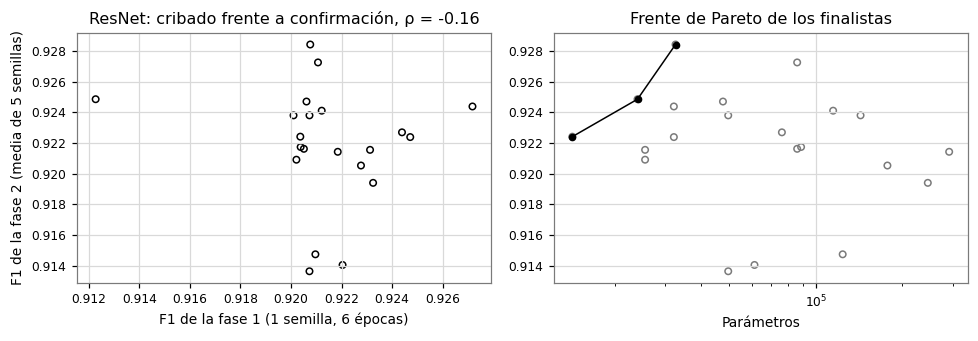

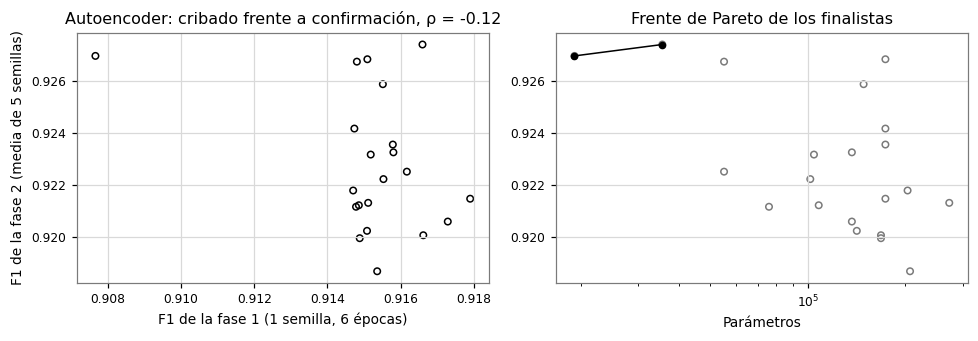

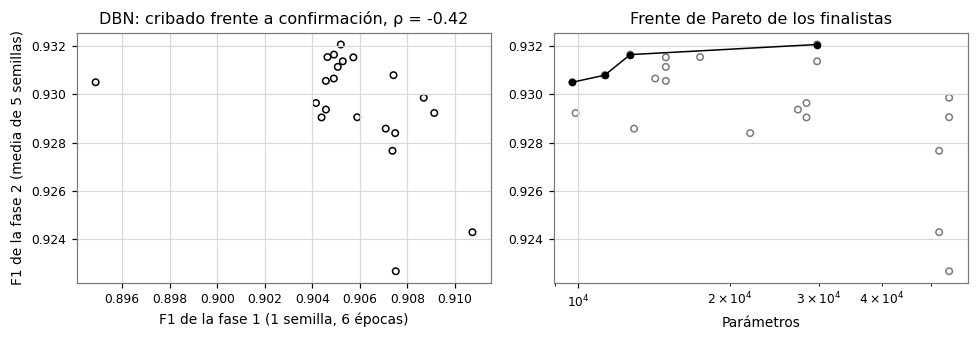

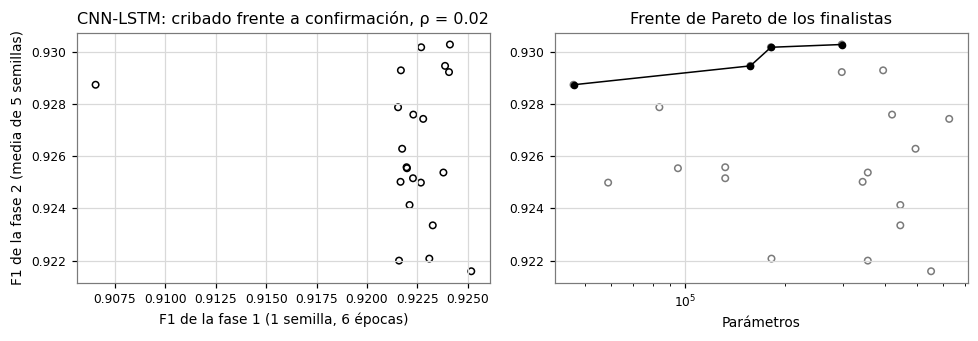

Modelo,Finalistas,Ganadora,F1 de validación (5 semillas),Parámetros,Mejor media,Empate técnico,Equivalentes por TOST,ρ de Spearman fase 1–fase 2,p,DE entre arquitecturas (fase 1),DE entre semillas (fase 2),Brecha entrenamiento − validación
ResNet,21,w64-32-32_d011,"0,9224",14 245,w128-16-64_d010,sí,15,"-0,161","0,486","0,0081","0,0074","0,0032"
Autoencoder,21,w64-64-64_d010,"0,9269",19 093,w64-128-64_d000,sí,8,"-0,121","0,602","0,0109","0,0070","0,0010"
DBN,21,w64-64-64_d010,"0,9305",9 733,w256-64-128_d011,sí,19,"-0,418","0,059","0,0982","0,0025","0,0014"
CNN-LSTM,21,w64-64-64_d010,"0,9287",46 213,w128-256-128_d000,sí,13,"0,025","0,915","0,0079","0,0049","0,0036"


Fase,Corridas,Horas de proceso
Ruido por semilla,60,"0,4"
Fase 1,4 000,"31,0"
Fase 2,420,"23,6"


Nota: 6 corridas estaban en curso cuando el equipo se suspendió; su resultado no cambia, porque el proceso continuó al reanudar, y a su tiempo de reloj se le descuenta la suspensión registrada por el sistema (resultados/corridas/suspensiones.json).


In [42]:
f2 = RES.tabla_fase("fase2")
detalle_f2 = ADENDA["fase2"]["detalle"]
filas_f2 = []
for m in CON_BUSQUEDA:
    sub2 = f2[f2["modelo"] == m]
    agg = sub2.groupby("arquitectura").agg(media=("f1_val", "mean"), de=("f1_val", "std"), f1_ent=("f1_ent", "mean"), segundos=("segundos", "mean"), parametros=("parametros", "first")).reset_index()
    agg["brecha"] = agg["f1_ent"] - agg["media"]
    fase1_m = f1[f1["modelo"] == m].set_index("arquitectura")["f1_val"]
    agg["fase1"] = agg["arquitectura"].map(fase1_m)
    rho = stats.spearmanr(agg["fase1"], agg["media"])
    ganadora = tuple(ADENDA["arquitecturas_ganadoras"][m])
    borde = any(w in (16, 256) for w in ganadora[:3]) and len({w for w in ganadora[:3]}) == 1
    filas_f2.append({"Modelo": m, "Finalistas": len(agg), "Ganadora": MOD.identificador(ganadora), "F1 de validación (5 semillas)": float(agg.loc[agg["arquitectura"] == ganadora, "media"].iloc[0]),
                     "Parámetros": int(agg.loc[agg["arquitectura"] == ganadora, "parametros"].iloc[0]), "Mejor media": detalle_f2[m]["mejor_media"], "Empate técnico": "sí" if detalle_f2[m]["empate_tecnico"] else "no",
                     "Equivalentes por TOST": len(detalle_f2[m]["equivalentes_tost"]), "ρ de Spearman fase 1–fase 2": rho.statistic, "p": rho.pvalue,
                     "DE entre arquitecturas (fase 1)": fase1_m.std(), "DE entre semillas (fase 2)": float(np.sqrt((sub2.groupby("arquitectura")["f1_val"].var()).mean())),
                     "Brecha entrenamiento − validación": float(agg.loc[agg["arquitectura"] == ganadora, "brecha"].iloc[0])})
    fig, ejes = plt.subplots(1, 2, figsize=(9, 3.2))
    ejes[0].scatter(agg["fase1"], agg["media"], s=18, facecolors="none", edgecolors=NEGRO)
    ejes[0].set_xlabel("F1 de la fase 1 (1 semilla, 6 épocas)")
    ejes[0].set_ylabel("F1 de la fase 2 (media de 5 semillas)")
    ejes[0].set_title(f"{m}: cribado frente a confirmación, ρ = {rho.statistic:.2f}")
    orden = agg.sort_values("parametros")
    frente = orden[orden["media"] >= orden["media"].cummax()]
    ejes[1].scatter(orden["parametros"], orden["media"], s=18, facecolors="none", edgecolors=GRIS_MEDIO)
    ejes[1].plot(frente["parametros"], frente["media"], color=NEGRO, marker="o", ms=4, lw=1)
    ejes[1].set_xscale("log")
    ejes[1].set_xlabel("Parámetros")
    ejes[1].set_title("Frente de Pareto de los finalistas")
    plt.tight_layout()
    plt.show()
FASE2 = pd.DataFrame(filas_f2)
FASE2.to_csv(RESULTADOS / "busqueda_fase2.csv", index=False, encoding="utf-8-sig")
tabla(FASE2, {"F1 de validación (5 semillas)": "{:.4f}", "Parámetros": "{:,.0f}", "ρ de Spearman fase 1–fase 2": "{:.3f}", "p": "{:.3f}", "DE entre arquitecturas (fase 1)": "{:.4f}",
              "DE entre semillas (fase 2)": "{:.4f}", "Brecha entrenamiento − validación": "{:.4f}"})
costo_busqueda = pd.DataFrame({"Fase": ["Ruido por semilla", "Fase 1", "Fase 2"], "Corridas": [len(ruido), len(f1), len(f2)],
                               "Horas de proceso": [ruido["segundos"].sum() / 3600, f1["segundos"].sum() / 3600, f2["segundos"].sum() / 3600]})
tabla(costo_busqueda, {"Horas de proceso": "{:.1f}"})
if RES.suspensiones():
    print(f"Nota: {len(RES.suspensiones())} corridas estaban en curso cuando el equipo se suspendió; su resultado no cambia, porque el proceso continuó al reanudar, "
          "y a su tiempo de reloj se le descuenta la suspensión registrada por el sistema (resultados/corridas/suspensiones.json).")

In [43]:
def mayor_factor(m):
    sub_e = efectos[(efectos["Modelo"] == m) & (~efectos["Factor"].str.startswith("tendencia")) & (efectos["Factor"] != "Residuo")]
    return sub_e.loc[sub_e["% de varianza"].idxmax()]
residuos = efectos[efectos["Factor"] == "Residuo"].set_index("Modelo")["% de varianza"]
textos_factor = [f"{m}, {mayor_factor(m)['Factor']} ({num(mayor_factor(m)['% de varianza'], 1)} %)" for m in CON_BUSQUEDA]
dp = pd.DataFrame(dropout_pareado).set_index("Modelo")
ayuda = [m for m in CON_BUSQUEDA if dp.loc[m, "p Wilcoxon"] < ALFA and dp.loc[m, "Diferencia media con dropout − sin dropout"] > 0]
perjudica = [m for m in CON_BUSQUEDA if dp.loc[m, "p Wilcoxon"] < ALFA and dp.loc[m, "Diferencia media con dropout − sin dropout"] < 0]
irrelevante = [r_["Modelo"] for _, r_ in FASE2.iterrows() if r_["DE entre arquitecturas (fase 1)"] <= 1.5 * r_["DE entre semillas (fase 2)"]]
borde = [r_["Modelo"] for _, r_ in FASE2.iterrows() if any(w in (16, 256) for w in ADENDA["arquitecturas_ganadoras"][r_["Modelo"]][:3])]
estimado_h = 126000 / 3600
REFERENCIA_ID = "w64-64-64_d010"
gana_referencia = FASE2.loc[FASE2["Ganadora"] == REFERENCIA_ID, "Modelo"].tolist()
con_empate = FASE2.loc[FASE2["Empate técnico"] == "sí", "Modelo"].tolist()
if not ayuda:
    texto_dropout = f"El *dropout* no mejora el F1 de forma significativa en ningún modelo" + (f" y lo empeora en {enumerar(perjudica)}" if perjudica else "")
else:
    texto_dropout = f"El *dropout* mejora el F1 de forma significativa en {enumerar(ayuda)}" + (f" y lo empeora en {enumerar(perjudica)}" if perjudica else "")
if gana_referencia:
    texto_referencia = (f" En {enumerar(con_empate)} hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros; "
                        f"en {enumerar(gana_referencia)}, esa elegida es la propia referencia (64, 64, 64) con *dropout* (0, 1, 0), de modo que la búsqueda no encontró en {'esos modelos' if len(gana_referencia) > 1 else 'ese modelo'} una arquitectura que la supere en más de δ.")
else:
    texto_referencia = f" En {enumerar(con_empate)} hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros." if con_empate else ""
interpretar(f'''**Interpretación.** En la fase 1, el factor que más varianza explica en cada modelo es: {enumerar(textos_factor)}; el residuo, que mezcla el ruido por semilla con lo que el modelo lineal no captura, va de {num(residuos.min(), 1)} % a {num(residuos.max(), 1)} %. {texto_dropout}, según la comparación pareada sobre las 125 combinaciones de anchos. En la fase 2, la correlación de rangos con la fase 1 va de {num(FASE2["ρ de Spearman fase 1–fase 2"].min(), 2)} a {num(FASE2["ρ de Spearman fase 1–fase 2"].max(), 2)}, y las ganadoras son {enumerar(FASE2["Modelo"] + ", " + FASE2["Ganadora"])}.{texto_referencia}

Esto significa que la fase 1 {"informó poco el orden de la fase 2 en " + enumerar(FASE2.loc[FASE2["ρ de Spearman fase 1–fase 2"] < 0.3, "Modelo"]) + ", de modo que en esos modelos la ganadora es la mejor entre los finalistas y no necesariamente la mejor de las 1000" if (FASE2["ρ de Spearman fase 1–fase 2"] < 0.3).any() else "ordenó a los finalistas de forma parecida a la fase 2"}. Así mismo, {"en " + enumerar(irrelevante) + " la dispersión entre arquitecturas es comparable a la dispersión entre semillas, de modo que la arquitectura es irrelevante para ese modelo en este problema, como prevé la sección 14.6 del enunciado" if irrelevante else "en todos los modelos la dispersión entre arquitecturas supera con claridad a la de semillas, de modo que la arquitectura sí importa"}. {"La ganadora tiene algún ancho en el borde del espacio (16 o 256) en " + enumerar(borde) + ", lo que se declara como limitación: el espacio podría no contener el óptimo, y no se amplía después de ver la prueba." if borde else "Ninguna ganadora cae en el borde del espacio."} Hay que tener en cuenta la maldición del ganador: la media de validación de la ganadora en la fase 2 está sesgada hacia arriba por la selección, y por eso su desempeño se estima solo con la prueba, en la ejecución definitiva.

Por lo anterior, conviene usar estas arquitecturas en la ejecución definitiva, como fijó la regla del preregistro, y leer su comparación con los demás modelos sabiendo que la búsqueda costó {num(costo_busqueda["Horas de proceso"].sum(), 1)} horas de proceso, frente a unas {num(estimado_h, 0)} que el preregistro estimó solo para la fase 1 con todos los datos, antes de la desviación 1.''')

**Interpretación.** En la fase 1, el factor que más varianza explica en cada modelo es: ResNet, w1 (67,0 %), Autoencoder, w1 (20,6 %), DBN, w3 (30,1 %) y CNN-LSTM, w2 (19,8 %); el residuo, que mezcla el ruido por semilla con lo que el modelo lineal no captura, va de 26,6 % a 67,1 %. El *dropout* no mejora el F1 de forma significativa en ningún modelo y lo empeora en ResNet, Autoencoder, DBN y CNN-LSTM, según la comparación pareada sobre las 125 combinaciones de anchos. En la fase 2, la correlación de rangos con la fase 1 va de -0,42 a 0,02, y las ganadoras son ResNet, w64-32-32_d011, Autoencoder, w64-64-64_d010, DBN, w64-64-64_d010 y CNN-LSTM, w64-64-64_d010. En ResNet, Autoencoder, DBN y CNN-LSTM hay empate técnico entre la mejor media y otras finalistas, y la regla del preregistro elige entre ellas la de menos parámetros; en Autoencoder, DBN y CNN-LSTM, esa elegida es la propia referencia (64, 64, 64) con *dropout* (0, 1, 0), de modo que la búsqueda no encontró en esos modelos una arquitectura que la supere en más de δ.

Esto significa que la fase 1 informó poco el orden de la fase 2 en ResNet, Autoencoder, DBN y CNN-LSTM, de modo que en esos modelos la ganadora es la mejor entre los finalistas y no necesariamente la mejor de las 1000. Así mismo, en ResNet la dispersión entre arquitecturas es comparable a la dispersión entre semillas, de modo que la arquitectura es irrelevante para ese modelo en este problema, como prevé la sección 14.6 del enunciado. Ninguna ganadora cae en el borde del espacio. Hay que tener en cuenta la maldición del ganador: la media de validación de la ganadora en la fase 2 está sesgada hacia arriba por la selección, y por eso su desempeño se estima solo con la prueba, en la ejecución definitiva.

Por lo anterior, conviene usar estas arquitecturas en la ejecución definitiva, como fijó la regla del preregistro, y leer su comparación con los demás modelos sabiendo que la búsqueda costó 55,1 horas de proceso, frente a unas 35 que el preregistro estimó solo para la fase 1 con todos los datos, antes de la desviación 1.

(sec-4-4)=
## 4.4 Buenas prácticas obligatorias contra la fuga de información

La tabla contrasta cada práctica de la sección 4.4 del enunciado con lo que se hace aquí; la evidencia de las verificaciones de datos está en la auditoría de la sección {ref}`2.1.4 <sec-2-1-4>`, y la prueba de sanidad con etiquetas permutadas, en la sección 7.

| Práctica | Cómo se cumple |
|---|---|
| Separar entrenamiento, validación y prueba | Partición heredada, sin bloques compartidos (sección {ref}`2.1.4 <sec-2-1-4>`) |
| Ajustar escaladores, imputadores y codificadores solo en entrenamiento | La estandarización y los pesos de clase usan solo entrenamiento, también en cada pliegue; prueba sintética aprobada |
| Evitar mezcla temporal o espacial | No aplica: no hay marca de tiempo ni coordenadas, y la partición agrupa por serie |
| Evitar fuga de duplicados entre particiones | Cero filas idénticas entre particiones; casi duplicados de prueba por debajo de la tolerancia y evaluados en la sección {ref}`4.5 <sec-4-5>` |
| No usar la prueba para seleccionar hiperparámetros, arquitecturas ni umbrales | Toda selección usa validación; el umbral de decisión es el arg max de las probabilidades, sin ajustar |
| Aplicar la misma validación a todos los modelos | Misma partición, mismas semillas y mismo presupuesto de ajuste |
| Ejecutar la auditoría formal de la sección 10 | Secciones {ref}`2.1.4 <sec-2-1-4>` y 7 |

(sec-4-5)=
## 4.5 Evaluación

Cada corrida definitiva evalúa la prueba una sola vez, con el modelo de la mejor época de validación, y guarda sus probabilidades. Aquí se calculan, para cada uno de los 16 modelos y sus R semillas, las métricas declaradas a priori, las curvas de entrenamiento, el costo, la brecha entre entrenamiento, validación y prueba, la calibración, los errores y el desempeño por segmentos. Las pruebas de hipótesis entre modelos están en la sección 6.

Los intervalos por bloques remuestrean con reemplazo los 24 bloques de prueba y recalculan el F1 macro sobre la matriz de confusión agregada de los bloques elegidos. Hay que tener en cuenta que cada bloque de prueba contiene solo una o dos clases (14 bloques con una y 10 con dos), de modo que el F1 macro de un bloque, de un segmento o de un remuestreo se promedia sobre las clases presentes en él: promediar sobre las cinco contaría como cero el F1 de una clase que no aparece, lo que no es un error del modelo. Sobre la prueba completa, con las cinco clases, las dos definiciones coinciden.

In [44]:
from codigo import analisis as AN

METRICAS, CONF_BLOQUES = AN.metricas_definitiva()
DEF = [r for r in RES.registros("definitiva")]
ORDEN = PROFUNDOS + ["LightGBM", "Logística", "Trivial"]
# El trivial es determinista: se repite su única corrida en todas las semillas para las pruebas pareadas
trivial = METRICAS[METRICAS["modelo"] == "Trivial"].iloc[0]
METRICAS = pd.concat([METRICAS[METRICAS["modelo"] != "Trivial"], pd.DataFrame([trivial.to_dict() | {"semilla": s} for s in SEMILLAS])], ignore_index=True)
METRICAS = METRICAS[METRICAS["semilla"].isin(SEMILLAS)]
assert METRICAS.groupby("modelo").size().eq(R).all(), "Faltan corridas definitivas"
def resumen(col):
    g = METRICAS.groupby("modelo")[col]
    media, de = g.mean(), g.std()
    margen = stats.t.ppf(0.975, R - 1) * de / np.sqrt(R)
    return media, de, media - margen, media + margen
NOMBRES_M = ["F1 macro", "Accuracy", "Balanced accuracy", "Precision macro", "Recall macro", "F1 ponderado", "AUC-ROC macro", "AUC-PR macro", "MCC", "Log-loss", "Brier", "ECE", "ECE adaptativo",
             "Confusión Blackhole–Wormhole"]
tabla_metricas = {}
for nombre in NOMBRES_M:
    media, de, bajo, alto = resumen(f"prueba {nombre}")
    tabla_metricas[nombre] = {m: f"{num(media[m], 4)} ± {num(de[m], 4)} [{num(bajo[m], 4)}; {num(alto[m], 4)}]" for m in ORDEN}
tabla(pd.DataFrame(tabla_metricas).loc[ORDEN].reset_index(names="Modelo"))
F1P = RES.matriz(METRICAS, "prueba F1 macro")[ORDEN]
F1V = RES.matriz(METRICAS, "validación F1 macro")[ORDEN]
TOP3 = F1V[PROFUNDOS].mean().sort_values(ascending=False).index[:3].tolist()
MEJOR_DL = TOP3[0]
print(f"Tres mejores modelos profundos por F1 macro medio de validación: {enumerar(TOP3)}")

Modelo,F1 macro,Accuracy,Balanced accuracy,Precision macro,Recall macro,F1 ponderado,AUC-ROC macro,AUC-PR macro,MCC,Log-loss,Brier,ECE,ECE adaptativo,Confusión Blackhole–Wormhole
DNN,"0,8577 ± 0,0084 [0,8537; 0,8616]","0,8634 ± 0,0088 [0,8593; 0,8676]","0,8643 ± 0,0085 [0,8603; 0,8682]","0,8581 ± 0,0088 [0,8539; 0,8622]","0,8643 ± 0,0085 [0,8603; 0,8682]","0,8641 ± 0,0087 [0,8601; 0,8682]","0,9617 ± 0,0037 [0,9600; 0,9635]","0,8387 ± 0,0082 [0,8349; 0,8425]","0,8283 ± 0,0112 [0,8231; 0,8336]","0,6489 ± 0,0291 [0,6352; 0,6625]","0,2209 ± 0,0143 [0,2142; 0,2276]","0,0499 ± 0,0069 [0,0466; 0,0531]","0,0496 ± 0,0072 [0,0463; 0,0530]","0,1521 ± 0,0133 [0,1458; 0,1583]"
CNN 1D,"0,8584 ± 0,0050 [0,8561; 0,8608]","0,8646 ± 0,0052 [0,8622; 0,8670]","0,8665 ± 0,0044 [0,8644; 0,8686]","0,8591 ± 0,0055 [0,8565; 0,8616]","0,8665 ± 0,0044 [0,8644; 0,8686]","0,8654 ± 0,0053 [0,8629; 0,8678]","0,9663 ± 0,0029 [0,9650; 0,9677]","0,8545 ± 0,0097 [0,8500; 0,8591]","0,8301 ± 0,0066 [0,8271; 0,8332]","0,6006 ± 0,0384 [0,5826; 0,6186]","0,2188 ± 0,0084 [0,2149; 0,2228]","0,0492 ± 0,0043 [0,0472; 0,0513]","0,0486 ± 0,0045 [0,0465; 0,0507]","0,1449 ± 0,0086 [0,1409; 0,1490]"
LSTM,"0,8285 ± 0,0259 [0,8164; 0,8406]","0,8391 ± 0,0244 [0,8276; 0,8505]","0,8343 ± 0,0265 [0,8219; 0,8467]","0,8300 ± 0,0270 [0,8173; 0,8426]","0,8343 ± 0,0265 [0,8219; 0,8467]","0,8394 ± 0,0244 [0,8280; 0,8508]","0,9690 ± 0,0080 [0,9653; 0,9728]","0,8532 ± 0,0318 [0,8383; 0,8681]","0,7976 ± 0,0313 [0,7829; 0,8122]","0,5252 ± 0,0648 [0,4949; 0,5555]","0,2513 ± 0,0338 [0,2355; 0,2671]","0,0553 ± 0,0117 [0,0498; 0,0608]","0,0543 ± 0,0116 [0,0489; 0,0598]","0,1569 ± 0,0293 [0,1432; 0,1707]"
CNN-LSTM,"0,8626 ± 0,0188 [0,8537; 0,8714]","0,8711 ± 0,0188 [0,8624; 0,8799]","0,8699 ± 0,0193 [0,8609; 0,8790]","0,8670 ± 0,0205 [0,8574; 0,8766]","0,8699 ± 0,0193 [0,8609; 0,8790]","0,8715 ± 0,0191 [0,8626; 0,8805]","0,9779 ± 0,0046 [0,9757; 0,9800]","0,8940 ± 0,0254 [0,8821; 0,9059]","0,8393 ± 0,0243 [0,8280; 0,8507]","0,4457 ± 0,0421 [0,4260; 0,4654]","0,2055 ± 0,0267 [0,1930; 0,2179]","0,0467 ± 0,0064 [0,0437; 0,0497]","0,0457 ± 0,0065 [0,0427; 0,0487]","0,1230 ± 0,0218 [0,1128; 0,1332]"
Autoencoder,"0,8591 ± 0,0095 [0,8546; 0,8635]","0,8650 ± 0,0102 [0,8602; 0,8698]","0,8643 ± 0,0091 [0,8600; 0,8686]","0,8603 ± 0,0109 [0,8552; 0,8654]","0,8643 ± 0,0091 [0,8600; 0,8686]","0,8657 ± 0,0101 [0,8609; 0,8704]","0,9631 ± 0,0040 [0,9612; 0,9650]","0,8479 ± 0,0142 [0,8412; 0,8545]","0,8303 ± 0,0132 [0,8241; 0,8365]","0,6443 ± 0,0365 [0,6272; 0,6614]","0,2168 ± 0,0155 [0,2096; 0,2241]","0,0485 ± 0,0054 [0,0460; 0,0510]","0,0480 ± 0,0055 [0,0454; 0,0506]","0,1457 ± 0,0178 [0,1373; 0,1540]"
RNN,"0,8371 ± 0,0201 [0,8277; 0,8465]","0,8427 ± 0,0209 [0,8329; 0,8525]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,8384 ± 0,0207 [0,8287; 0,8481]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,8430 ± 0,0211 [0,8332; 0,8529]","0,9652 ± 0,0056 [0,9625; 0,9678]","0,8534 ± 0,0188 [0,8446; 0,8622]","0,8022 ± 0,0267 [0,7896; 0,8147]","0,6182 ± 0,0467 [0,5963; 0,6400]","0,2482 ± 0,0293 [0,2345; 0,2619]","0,0638 ± 0,0113 [0,0585; 0,0691]","0,0635 ± 0,0112 [0,0583; 0,0688]","0,1718 ± 0,0303 [0,1576; 0,1860]"
Transformer,"0,8576 ± 0,0127 [0,8517; 0,8636]","0,8644 ± 0,0136 [0,8580; 0,8708]","0,8655 ± 0,0115 [0,8601; 0,8708]","0,8594 ± 0,0136 [0,8530; 0,8657]","0,8655 ± 0,0115 [0,8601; 0,8708]","0,8650 ± 0,0135 [0,8587; 0,8714]","0,9744 ± 0,0047 [0,9722; 0,9766]","0,8843 ± 0,0197 [0,8751; 0,8935]","0,8301 ± 0,0172 [0,8221; 0,8382]","0,5221 ± 0,0584 [0,4947; 0,5494]","0,2171 ± 0,0175 [0,2089; 0,2253]","0,0484 ± 0,0043 [0,0464; 0,0504]","0,0480 ± 0,0047 [0,0458; 0,0502]","0,1410 ± 0,0225 [0,1304; 0,1515]"
BiLSTM,"0,8457 ± 0,0238 [0,8346; 0,8568]","0,8543 ± 0,0239 [0,8431; 0,8655]","0,8534 ± 0,0233 [0,8425; 0,8643]","0,8489 ± 0,0236 [0,8378; 0,8600]","0,8534 ± 0,0233 [0,8425; 0,8643]","0,8547 ± 0,0243 [0,8433; 0,8661]","0,9747 ± 0,0050 [0,9724; 0,9771]","0,8932 ± 0,0179 [0,8848; 0,9016]","0,8177 ± 0,0299 [0,8038; 0,8317]","0,4674 ± 0,0395

Tres mejores modelos profundos por F1 macro medio de validación: CNN 1D, KAN y DBN


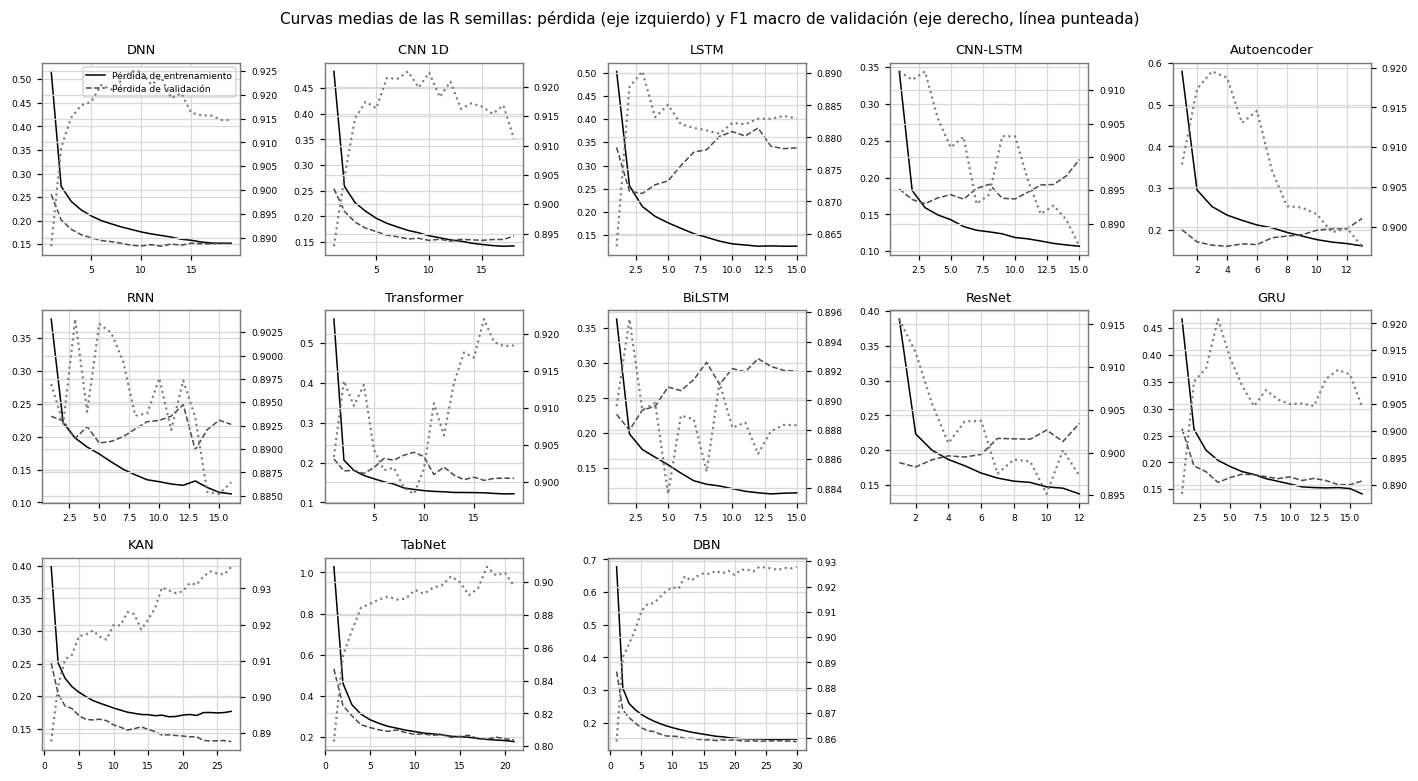

Modelo,Parámetros,MAC,Épocas,Mejor época,Minutos,Latencia por muestra (ms),ms por muestra en lote,Memoria pico del proceso (MB),FLOPs,Muestras por segundo,kWh estimados (R corridas)
DNN,12 677,12 448,"15,3","9,3","0,68","0,400","0,0017",829,24 896,589 797,"0,0007"
CNN 1D,39 493,132 928,"15,2","9,2","1,97","1,594","0,0254",819,265 856,39 389,"0,0020"
LSTM,17 477,266 560,"9,3","3,4","2,63","2,115","0,0487",819,533 120,20 514,"0,0026"
CNN-LSTM,46 213,462 144,"9,6","3,6","3,39","3,206","0,0645",824,924 288,15 511,"0,0034"
Autoencoder,19 093,9 536,"10,5","4,5","0,59","0,298","0,0012",819,19 072,809 717,"0,0006"
RNN,38 277,469 632,"10,1","4,0","3,75","4,532","0,0443",829,939 264,22 598,"0,0038"
Transformer,3 381,11 072,"9,8","3,8","0,86","1,348","0,0175",829,22 144,57 014,"0,0009"
BiLSTM,530 693,8 406 272,"9,1","3,1","33,87","10,539","0,9625",824,16 812 544,1 039,"0,0339"
ResNet,14 245,13 472,"8,7","2,7","0,81","0,890","0,0024",819,26 944,420 875,"0,0008"
GRU,96 901,1 391 232,"11,1","5,1","14,78","12,616","0,2105",824,2 782 464,4 751,"0,0148"


Hardware: Intel64 Family 6 Model 154 Stepping 4, GenuineIntel, 10 hilos disponibles; cada corrida usó 2 hilos. Energía estimada con la potencia base del procesador (15 W) repartida entre los 10 núcleos.


In [45]:
cur = RES.curvas("definitiva")
fig, ejes = plt.subplots(3, 5, figsize=(13, 7.2), sharey=False)
for eje, m in zip(ejes.ravel(), PROFUNDOS):
    c = cur[cur["modelo"] == m]
    agg = c.groupby("epoca")[["perdida_ent", "perdida_val", "f1_val"]].mean()
    eje.plot(agg.index, agg["perdida_ent"], color=NEGRO, lw=1, label="Pérdida de entrenamiento")
    eje.plot(agg.index, agg["perdida_val"], color=GRIS_OSCURO, ls="--", lw=1, label="Pérdida de validación")
    eje2 = eje.twinx()
    eje2.plot(agg.index, agg["f1_val"], color=GRIS_MEDIO, ls=":", lw=1.4, label="F1 de validación")
    eje2.tick_params(labelsize=6)
    eje.set_title(m, fontsize=8.5)
    eje.tick_params(labelsize=6)
for eje in ejes.ravel()[len(PROFUNDOS):]:
    eje.axis("off")
ejes[0, 0].legend(fontsize=6, loc="upper right")
fig.suptitle("Curvas medias de las R semillas: pérdida (eje izquierdo) y F1 macro de validación (eje derecho, línea punteada)", fontsize=10)
plt.tight_layout()
plt.show()
costo = METRICAS.groupby("modelo").agg(Parámetros=("parametros", "first"), MAC=("mac", "first"), Épocas=("epocas", "mean"), Mejor_época=("mejor_epoca", "mean"),
                                       Minutos=("segundos", lambda s: s.mean() / 60), ms_por_muestra=("ms_por_muestra", "median"), ms_lote=("ms_por_muestra_lote", "median"),
                                       Memoria_MB=("memoria_pico_mb", "median")).loc[ORDEN]
costo["FLOPs"] = 2 * costo["MAC"]
costo["Muestras por segundo"] = 1000 / costo["ms_lote"]
ENERGIA_W = 15.0
costo["kWh estimados (R corridas)"] = costo["Minutos"] * 60 * R * ENERGIA_W / 3.6e6 * 2 / 10
tabla(costo.reset_index(names="Modelo").rename(columns={"Mejor_época": "Mejor época", "ms_por_muestra": "Latencia por muestra (ms)", "ms_lote": "ms por muestra en lote", "Memoria_MB": "Memoria pico del proceso (MB)"}),
      {"Parámetros": "{:,.0f}", "MAC": "{:,.0f}", "FLOPs": "{:,.0f}", "Épocas": "{:.1f}", "Mejor época": "{:.1f}", "Minutos": "{:.2f}", "Latencia por muestra (ms)": "{:.3f}",
       "ms por muestra en lote": "{:.4f}", "Memoria pico del proceso (MB)": "{:.0f}", "Muestras por segundo": "{:,.0f}", "kWh estimados (R corridas)": "{:.4f}"})
print(f"Hardware: {platform.processor()}, {torch.get_num_threads()} hilos disponibles; cada corrida usó 2 hilos. Energía estimada con la potencia base del procesador ({ENERGIA_W:g} W) repartida entre los 10 núcleos.")

**Fichas de modelo y registro de experimentos.** La tabla sigue la plantilla 11.3 del enunciado para los 16 modelos, y el registro consolidado de todas las corridas, de todas las fases, con su configuración, semilla y resultados, queda en `resultados/registro_experimentos.csv`.

In [46]:
fases_registro = ["ajuste", "piloto", "ruido", "fase1", "fase2", "definitiva", "cv5x2", "ablacion", "curvas", "permutacion", "bootstrap"]
registro_exp = pd.concat([RES.tabla_fase(f) for f in fases_registro if len(RES.tabla_fase(f))], ignore_index=True)
columnas_reg = [c for c in ["id", "fase", "modelo", "semilla", "arquitectura", "hp_lr", "hp_weight_decay", "hp_batch", "particion", "max_epocas", "epocas", "mejor_epoca", "divergente",
                            "f1_ent", "f1_val", "f1_eva", "segundos", "memoria_pico_mb", "equipo"] if c in registro_exp.columns]
registro_exp[columnas_reg].to_csv(RESULTADOS / "registro_experimentos.csv", index=False, encoding="utf-8-sig")
DOI_FUENTE = {"DNN": "10.1109/cns66487.2025.11194990", "CNN 1D": "10.1109/cns66487.2025.11194990", "LSTM": "10.1109/cns66487.2025.11194990", "RNN": "10.1038/s41598-026-45063-6",
              "GRU": "10.1038/s41598-026-45063-6", "Transformer": "10.1038/s41598-026-45063-6", "BiLSTM": "ijisae.org/index.php/IJISAE/article/view/8549", "KAN": "10.1016/j.sysarc.2026.104038",
              "TabNet": "10.1609/aaai.v35i8.16826", "ResNet": "10.1109/cvpr.2016.90", "Autoencoder": "10.1126/science.1127647", "DBN": "10.1162/neco.2006.18.7.1527",
              "CNN-LSTM": "10.1109/cvpr.2015.7298878", "LightGBM": "lightgbm 4.7.0", "Logística": "scikit-learn 1.9.0", "Trivial": "Clase mayoritaria"}
commit = subprocess.run(["git", "-C", str(RAIZ_E2), "log", "-1", "--format=%h", "--", "codigo"], capture_output=True, text=True).stdout.strip() or "sin repositorio"
fichas = []
for m in ORDEN:
    sub_m = METRICAS[METRICAS["modelo"] == m]
    arq = ADENDA.get("arquitecturas_ganadoras", {}).get(m)
    fichas.append({"Modelo": m, "Familia": MOD.CATALOGO[m]["familia"] if m in MOD.CATALOGO else "No profundo", "Referencia o versión": DOI_FUENTE[m], "Implementación": f"codigo/, commit {commit}",
                   "Preentrenamiento": "Ninguno", "Parámetros": costo.loc[m, "Parámetros"], "FLOPs por muestra": costo.loc[m, "FLOPs"],
                   "Hiperparámetros finales": ", ".join(f"{k} {cientifico(v)}" if isinstance(v, float) else f"{k} {v}" for k, v in MEJORES_HP.get(m, {}).items()) or "No aplica",
                   "Intentos de ajuste": int((ajuste["modelo"] == m).sum()), "Arquitectura seleccionada": MOD.identificador(arq) if arq else "Definida en la literatura" if m in MOD.CATALOGO else "No aplica",
                   "Entrenamiento": "Adam, ReduceLROnPlateau, parada por F1 de validación, float32" if m in MOD.CATALOGO else "Parada por log-loss de validación" if m == "LightGBM" else "lbfgs" if m == "Logística" else "No aplica",
                   "Épocas efectivas (media)": costo.loc[m, "Épocas"], "Minutos por corrida": costo.loc[m, "Minutos"], "Latencia (ms)": costo.loc[m, "ms_por_muestra"],
                   "Corridas definitivas": len(sub_m), "Incidencias": f"{int(registro_exp.loc[registro_exp['modelo'] == m, 'divergente'].fillna(False).astype(bool).sum())} corridas divergentes"})
FICHAS = pd.DataFrame(fichas)
FICHAS.to_csv(RESULTADOS / "fichas_de_modelo.csv", index=False, encoding="utf-8-sig")
tabla(FICHAS, {"Parámetros": "{:,.0f}", "FLOPs por muestra": "{:,.0f}", "Épocas efectivas (media)": "{:.1f}", "Minutos por corrida": "{:.2f}", "Latencia (ms)": "{:.3f}"})
print(f"Registro de experimentos: {len(registro_exp):,} corridas en {registro_exp['fase'].nunique()} fases".replace(",", " "))

Modelo,Familia,Referencia o versión,Implementación,Preentrenamiento,Parámetros,FLOPs por muestra,Hiperparámetros finales,Intentos de ajuste,Arquitectura seleccionada,Entrenamiento,Épocas efectivas (media),Minutos por corrida,Latencia (ms),Corridas definitivas,Incidencias
DNN,Perceptrón multicapa,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,12 677,24 896,"lr 10⁻³, weight_decay 0, batch 256",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","15,3","0,68","0,400",20,0 corridas divergentes
CNN 1D,Convolucional,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,39 493,265 856,"lr 10⁻³, weight_decay 0, batch 512",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","15,2","1,97","1,594",20,0 corridas divergentes
LSTM,Recurrente,10.1109/cns66487.2025.11194990,"codigo/, commit 585802a",Ninguno,17 477,533 120,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 128",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,3","2,63","2,115",20,0 corridas divergentes
CNN-LSTM,Híbrida,10.1109/cvpr.2015.7298878,"codigo/, commit 585802a",Ninguno,46 213,924 288,"lr 3 × 10⁻³, weight_decay 0, batch 256",12,w64-64-64_d010,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,6","3,39","3,206",20,0 corridas divergentes
Autoencoder,Codificador-decodificador,10.1126/science.1127647,"codigo/, commit 585802a",Ninguno,19 093,19 072,"lr 3 × 10⁻³, weight_decay 0, batch 256",12,w64-64-64_d010,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","10,5","0,59","0,298",20,0 corridas divergentes
RNN,Recurrente,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,38 277,939 264,"lr 3 × 10⁻³, weight_decay 10⁻⁴, batch 512",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","10,1","3,75","4,532",20,0 corridas divergentes
Transformer,Atención,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,3 381,22 144,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 512",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,8","0,86","1,348",20,0 corridas divergentes
BiLSTM,Recurrente,ijisae.org/index.php/IJISAE/article/view/8549,"codigo/, commit 585802a",Ninguno,530 693,16 812 544,"lr 3 × 10⁻³, weight_decay 10⁻⁵, batch 128",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","9,1","33,87","10,539",20,0 corridas divergentes
ResNet,Residual,10.1109/cvpr.2016.90,"codigo/, commit 585802a",Ninguno,14 245,26 944,"lr 10⁻³, weight_decay 0, batch 256",12,w64-32-32_d011,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","8,7","0,81","0,890",20,0 corridas divergentes
GRU,Recurrente,10.1038/s41598-026-45063-6,"codigo/, commit 585802a",Ninguno,96 901,2 782 464,"lr 10⁻³, weight_decay 0, batch 256",12,Definida en la literatura,"Adam, ReduceLROnPlateau, parada por F1 de validación, float32","11,1","14,78","12,616",20,0 corridas divergentes


Registro de experimentos: 6 271 corridas en 11 fases


**Ajuste, sobreajuste y consistencia entre validación y prueba.** Para cada modelo se calcula la brecha entre entrenamiento y validación, $g = s_{ent} - s_{val}$, y se prueba la hipótesis de no inferioridad de la tabla B: $H_0$: la mediana de $g$ es al menos δg = 0,05, frente a $H_1$: es menor, con Wilcoxon unilateral sobre $g - δ_g$ en las R semillas. La diferencia entre validación y prueba se estima con su IC 95 % por *bootstrap* por bloques, remuestreando por separado los bloques de cada conjunto, porque son series distintas.

In [47]:
NB_ENT = len(np.unique(bloques[ID_ENT]))
NB_VAL = len(np.unique(bloques[ID_VAL]))
NB_PRU = len(np.unique(bloques[ID_PRU]))
W_VAL, W_PRU = AN.pesos_bootstrap(NB_VAL, semilla=1), AN.pesos_bootstrap(NB_PRU, semilla=2)
def f1_bootstrap(modelo, conjunto):
    filas_m = METRICAS[METRICAS["modelo"] == modelo]
    W = W_VAL if conjunto == "val" else W_PRU
    return np.mean([AN.f1_desde_conteos(W @ CONF_BLOQUES[f"{i}|{conjunto}"]) for i in filas_m["id"]], 0)
brechas = []
for m in ORDEN:
    sub_m = METRICAS[METRICAS["modelo"] == m]
    g = (sub_m["f1_ent"] - sub_m["validación F1 macro"]).to_numpy()
    p_g = stats.wilcoxon(g - DELTA_G, alternative="less").pvalue if np.any(g != DELTA_G) else 1.0
    dif_boot = f1_bootstrap(m, "val") - f1_bootstrap(m, "eva")
    brechas.append({"Modelo": m, "F1 de entrenamiento": sub_m["f1_ent"].mean(), "F1 de validación": sub_m["validación F1 macro"].mean(), "F1 de prueba": sub_m["prueba F1 macro"].mean(),
                    "Brecha g": g.mean(), "p Wilcoxon (g < δg)": p_g, "Validación − prueba": sub_m["validación F1 macro"].mean() - sub_m["prueba F1 macro"].mean(),
                    "IC 95 % por bloques": intervalo(E.ic_percentil(dif_boot))})
BRECHAS = pd.DataFrame(brechas)
tabla(BRECHAS, {"F1 de entrenamiento": "{:.4f}", "F1 de validación": "{:.4f}", "F1 de prueba": "{:.4f}", "Brecha g": "{:+.4f}", "p Wilcoxon (g < δg)": "{:.2e}", "Validación − prueba": "{:+.4f}"})
bp = BRECHAS[BRECHAS["Modelo"].isin(PROFUNDOS)]
vp = BRECHAS.set_index("Modelo")["Validación − prueba"]
caida_dl, caida_lgbm, caida_log = vp.loc[PROFUNDOS].median(), vp.get("LightGBM", np.nan), vp.get("Logística", np.nan)
if caida_dl > DELTA and caida_lgbm < caida_dl / 2:
    lectura_caida = (f"la caída entre validación y prueba es común a los modelos profundos (mediana de {num(caida_dl, 4)}) y a la regresión logística ({num(caida_log, 4)}), pero mucho menor en LightGBM "
                     f"({num(caida_lgbm, 4)}). Es decir, depende de qué series cayeron en cada conjunto y también del tipo de modelo: una hipótesis, que la sección 6.3 contrasta con la validación cruzada, "
                     "es que los árboles, que parten cada atributo por umbrales, son menos sensibles a los cambios de escala y de forma de las distribuciones entre series que las redes y el modelo lineal, "
                     "que dependen de combinaciones continuas de los atributos")
elif caida_dl > DELTA:
    lectura_caida = ("la caída entre validación y prueba es común a casi todos los modelos, incluidos los que no se seleccionaron con validación, como la regresión logística, de modo que se explica más "
                     "por qué series cayeron en cada conjunto que por un sobreajuste a la validación")
else:
    lectura_caida = "la caída entre validación y prueba es pequeña, de modo que la prueba es consistente con la validación"
con_ic_cero = [f["Modelo"] for _, f in BRECHAS.iterrows() if float(f["IC 95 % por bloques"].strip("[]").split("; ")[0].replace(",", ".")) <= 0 <= float(f["IC 95 % por bloques"].strip("[]").split("; ")[1].replace(",", "."))]
interpretar(f'''**Interpretación.** En los 13 modelos profundos, la brecha entre entrenamiento y validación va de {num(bp["Brecha g"].min(), 4)} ({bp.loc[bp["Brecha g"].idxmin(), "Modelo"]}) a {num(bp["Brecha g"].max(), 4)} ({bp.loc[bp["Brecha g"].idxmax(), "Modelo"]}), y la prueba de no inferioridad confirma que es menor que δg = 0,05 en {int((bp["p Wilcoxon (g < δg)"] < ALFA).sum())} de ellos. La diferencia entre validación y prueba va de {num(BRECHAS["Validación − prueba"].min(), 4)} a {num(BRECHAS["Validación − prueba"].max(), 4)}, y su IC por bloques contiene al cero en {len(con_ic_cero)} de los {len(BRECHAS)} modelos.

Esto significa que {"ningún modelo sobreajusta el entrenamiento más allá del margen" if (bp["p Wilcoxon (g < δg)"] < ALFA).all() else "algunos modelos no demuestran una brecha menor que el margen"}, y que {lectura_caida}. Hay que tener en cuenta que, con solo {NB_VAL} bloques de validación y {NB_PRU} de prueba, el intervalo por bloques es amplio, porque la unidad independiente es la serie y no el flujo.

Por tal motivo, se reporta el desempeño de prueba con su intervalo por bloques en la tabla principal, y la brecha entre validación y prueba entra en el criterio de adecuación de la sección 7.''')

Modelo,F1 de entrenamiento,F1 de validación,F1 de prueba,Brecha g,p Wilcoxon (g < δg),Validación − prueba,IC 95 % por bloques
DNN,"0,9306","0,9283","0,8577","+0,0023","9,54e-07","+0,0706","[-0,0456; 0,1921]"
CNN 1D,"0,9331","0,9299","0,8584","+0,0032","9,54e-07","+0,0715","[-0,0408; 0,1930]"
LSTM,"0,9155","0,9037","0,8285","+0,0118","9,54e-07","+0,0752","[-0,0560; 0,1995]"
CNN-LSTM,"0,9343","0,9244","0,8626","+0,0099","9,54e-07","+0,0619","[-0,0570; 0,1849]"
Autoencoder,"0,9297","0,9275","0,8591","+0,0022","9,54e-07","+0,0685","[-0,0431; 0,1904]"
RNN,"0,9229","0,9191","0,8371","+0,0038","9,54e-07","+0,0820","[-0,0285; 0,2029]"
Transformer,"0,9286","0,9219","0,8576","+0,0068","9,54e-07","+0,0642","[-0,0443; 0,1867]"
BiLSTM,"0,9243","0,9089","0,8457","+0,0154","2,86e-06","+0,0632","[-0,0597; 0,1854]"
ResNet,"0,9254","0,9225","0,8510","+0,0030","9,54e-07","+0,0715","[-0,0427; 0,1929]"
GRU,"0,9266","0,9252","0,8474","+0,0014","9,54e-07","+0,0778","[-0,0374; 0,2010]"


**Interpretación.** En los 13 modelos profundos, la brecha entre entrenamiento y validación va de -0,0019 (KAN) a 0,0154 (BiLSTM), y la prueba de no inferioridad confirma que es menor que δg = 0,05 en 13 de ellos. La diferencia entre validación y prueba va de 0,0025 a 0,0937, y su IC por bloques contiene al cero en 16 de los 16 modelos.

Esto significa que ningún modelo sobreajusta el entrenamiento más allá del margen, y que la caída entre validación y prueba es común a los modelos profundos (mediana de 0,0715) y a la regresión logística (0,0937), pero mucho menor en LightGBM (0,0123). Es decir, depende de qué series cayeron en cada conjunto y también del tipo de modelo: una hipótesis, que la sección {ref}`6.3 <sec-6-3>` contrasta con la validación cruzada, es que los árboles, que parten cada atributo por umbrales, son menos sensibles a los cambios de escala y de forma de las distribuciones entre series que las redes y el modelo lineal, que dependen de combinaciones continuas de los atributos. Hay que tener en cuenta que, con solo 19 bloques de validación y 24 de prueba, el intervalo por bloques es amplio, porque la unidad independiente es la serie y no el flujo.

Por tal motivo, se reporta el desempeño de prueba con su intervalo por bloques en la tabla principal, y la brecha entre validación y prueba entra en el criterio de adecuación de la sección 7.

Modelo,T,ECE,ECE con T,ECE adaptativo,ECE adaptativo con T,Brier,Brier con T
DNN,"0,9500","0,0499","0,0507","0,0496","0,0502","0,2209","0,2211"
CNN 1D,"0,9527","0,0492","0,0506","0,0486","0,0498","0,2188","0,2191"
LSTM,"1,0078","0,0553","0,0585","0,0543","0,0574","0,2513","0,2520"
CNN-LSTM,"0,9895","0,0467","0,0476","0,0457","0,0469","0,2055","0,2057"
Autoencoder,"1,0009","0,0485","0,0489","0,0480","0,0484","0,2168","0,2170"
RNN,"1,0346","0,0638","0,0624","0,0635","0,0619","0,2482","0,2478"
Transformer,"1,0425","0,0484","0,0490","0,0480","0,0485","0,2171","0,2172"
BiLSTM,"1,1005","0,0506","0,0490","0,0496","0,0486","0,2258","0,2255"
ResNet,"0,9663","0,0540","0,0542","0,0530","0,0534","0,2298","0,2299"
GRU,"0,9612","0,0528","0,0544","0,0527","0,0541","0,2312","0,2318"


**Interpretación.** Sin recalibrar, el ECE de los modelos profundos va de 0,0467 (CNN-LSTM) a 0,0638 (RNN), y el de LightGBM es de 0,0356. La temperatura ajustada en validación es mayor que 1 en 5 de los 13 modelos profundos, y con ella el ECE medio pasa de 0,0523 a 0,0534; la versión adaptativa, con bins de igual tamaño, cambia de 0,0518 a 0,0528.

Lo anterior indica que la mayoría de los modelos profundos es subconfiada en validación, porque la temperatura que la corrige, menor que 1, agudiza las probabilidades, lo que es coherente con la pérdida ponderada por clase, que empuja probabilidad hacia las clases minoritarias, y que una sola temperatura ajustada en validación no mejora la calibración en prueba, lo que es coherente con que validación y prueba sean series distintas. Las temperaturas quedan entre 0,90 y 1,10, muy cerca de 1, de modo que en validación los modelos ya están casi calibrados y el ECE de prueba refleja sobre todo el cambio entre series. Así mismo, el ECE adaptativo confirma la lectura del de bins fijos, de modo que la conclusión no depende de la discretización.

Por lo anterior, conviene usar las probabilidades sin recalibrar, porque la temperatura de validación no las mejora en series nuevas, y declarar en el criterio de adecuación cuáles modelos quedan calibrados; recalibrar con datos de la serie de destino queda como requisito de una puesta en producción.

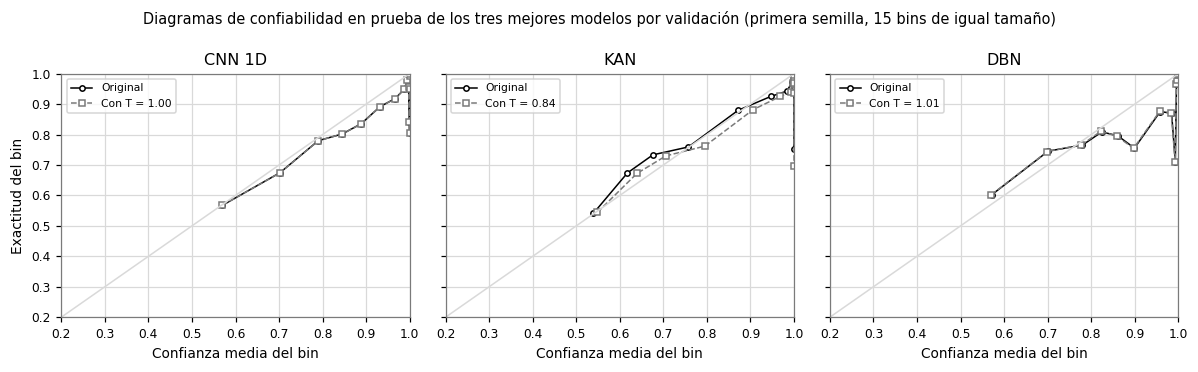

In [48]:
calib = []
for m in ORDEN:
    if m == "Trivial":
        continue
    for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]:
        r = next(x for x in DEF if x["id"] == i)
        p_val, p_eva = AN.prob(r, "val"), AN.prob(r, "eva")
        T = E.escalar_temperatura(E.logits_de(p_val), y[ID_VAL])
        p_cal = E.suavizar(p_eva, T)
        calib.append({"modelo": m, "semilla": r["semilla"], "T": T, "ECE": E.ece(p_eva, y[ID_PRU]), "ECE con T": E.ece(p_cal, y[ID_PRU]), "ECE adaptativo": E.ece(p_eva, y[ID_PRU], adaptativo=True),
                      "ECE adaptativo con T": E.ece(p_cal, y[ID_PRU], adaptativo=True), "Brier": E.brier(p_eva, y[ID_PRU]), "Brier con T": E.brier(p_cal, y[ID_PRU])})
CALIB = pd.DataFrame(calib)
tabla(CALIB.groupby("modelo").mean(numeric_only=True).drop(columns="semilla").loc[[m for m in ORDEN if m != "Trivial"]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ["T", "ECE", "ECE con T", "ECE adaptativo", "ECE adaptativo con T", "Brier", "Brier con T"]})
cal_m = CALIB.groupby("modelo").mean(numeric_only=True)
cal_p = cal_m.loc[PROFUNDOS]
interpretar(f'''**Interpretación.** Sin recalibrar, el ECE de los modelos profundos va de {num(cal_p["ECE"].min(), 4)} ({cal_p["ECE"].idxmin()}) a {num(cal_p["ECE"].max(), 4)} ({cal_p["ECE"].idxmax()}), y el de LightGBM es de {num(cal_m.loc["LightGBM", "ECE"], 4)}. La temperatura ajustada en validación es mayor que 1 en {int((cal_p["T"] > 1).sum())} de los 13 modelos profundos, y con ella el ECE medio pasa de {num(cal_p["ECE"].mean(), 4)} a {num(cal_p["ECE con T"].mean(), 4)}; la versión adaptativa, con bins de igual tamaño, cambia de {num(cal_p["ECE adaptativo"].mean(), 4)} a {num(cal_p["ECE adaptativo con T"].mean(), 4)}.

Lo anterior indica que {"la mayoría de los modelos profundos es sobreconfiada en validación, porque la temperatura que la corrige, mayor que 1, suaviza las probabilidades" if (cal_p["T"] > 1).sum() > 6 else "la mayoría de los modelos profundos es subconfiada en validación, porque la temperatura que la corrige, menor que 1, agudiza las probabilidades, lo que es coherente con la pérdida ponderada por clase, que empuja probabilidad hacia las clases minoritarias" if (cal_p["T"] < 1).sum() > 6 else "los modelos profundos se reparten entre sobreconfiados y subconfiados en validación"}, y que una sola temperatura ajustada en validación {"corrige buena parte del error de calibración en prueba" if cal_p["ECE con T"].mean() < cal_p["ECE"].mean() else "no mejora la calibración en prueba, lo que es coherente con que validación y prueba sean series distintas"}. {f"Las temperaturas quedan entre {num(cal_p['T'].min(), 2)} y {num(cal_p['T'].max(), 2)}, muy cerca de 1, de modo que en validación los modelos ya están casi calibrados y el ECE de prueba refleja sobre todo el cambio entre series. " if (cal_p["T"] - 1).abs().max() <= 0.12 else ""}Así mismo, el ECE adaptativo {"confirma la lectura del de bins fijos, de modo que la conclusión no depende de la discretización" if np.sign(cal_p["ECE con T"].mean() - cal_p["ECE"].mean()) == np.sign(cal_p["ECE adaptativo con T"].mean() - cal_p["ECE adaptativo"].mean()) else "cambia en sentido contrario al de bins fijos, de modo que la conclusión sobre la temperatura depende de la discretización"}.

{"Por lo anterior, conviene reportar las probabilidades con la temperatura de validación cuando se usen como puntaje de riesgo, y declarar en el criterio de adecuación cuáles modelos quedan calibrados." if cal_p["ECE con T"].mean() < cal_p["ECE"].mean() else "Por lo anterior, conviene usar las probabilidades sin recalibrar, porque la temperatura de validación no las mejora en series nuevas, y declarar en el criterio de adecuación cuáles modelos quedan calibrados; recalibrar con datos de la serie de destino queda como requisito de una puesta en producción."}''')
fig, ejes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for eje, m in zip(ejes, TOP3):
    r = next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0])
    p_eva = AN.prob(r, "eva")
    T = E.escalar_temperatura(E.logits_de(AN.prob(r, "val")), y[ID_VAL])
    for p, estilo, etq in ((p_eva, dict(color=NEGRO, marker="o"), "Original"), (E.suavizar(p_eva, T), dict(color=GRIS_MEDIO, marker="s", ls="--"), f"Con T = {T:.2f}")):
        conf, acierto = p.max(1), p.argmax(1) == y[ID_PRU]
        cortes = np.quantile(conf, np.linspace(0, 1, 16))
        idx = np.clip(np.digitize(conf, cortes[1:-1]), 0, 14)
        eje.plot([conf[idx == b].mean() for b in range(15)], [acierto[idx == b].mean() for b in range(15)], ms=3.5, lw=1, label=etq, mfc="white", **estilo)
    eje.plot([0, 1], [0, 1], color=GRIS_CLARO, lw=1)
    eje.set(title=m, xlabel="Confianza media del bin", xlim=(0.2, 1), ylim=(0.2, 1))
    eje.legend(fontsize=7)
ejes[0].set_ylabel("Exactitud del bin")
fig.suptitle("Diagramas de confiabilidad en prueba de los tres mejores modelos por validación (primera semilla, 15 bins de igual tamaño)", fontsize=9.5)
plt.tight_layout()
plt.show()

Modelo,Categoría,Errores,% de los errores,IC 95 % por bloques
CNN 1D,Confusión Blackhole–Wormhole,1 463,"46,7","[20,0; 82,7]"
CNN 1D,Ataque predicho como Normal,100,"3,2","[0,9; 7,9]"
CNN 1D,Normal predicho como ataque,178,"5,7","[0,4; 16,8]"
CNN 1D,Otras confusiones entre ataques,1 394,"44,5","[5,3; 73,8]"
KAN,Confusión Blackhole–Wormhole,1 414,"45,3","[21,0; 81,8]"
KAN,Ataque predicho como Normal,108,"3,5","[0,9; 8,1]"
KAN,Normal predicho como ataque,96,"3,1","[0,1; 9,7]"
KAN,Otras confusiones entre ataques,1 501,"48,1","[7,2; 74,7]"
DBN,Confusión Blackhole–Wormhole,1 576,"48,5","[20,2; 81,3]"
DBN,Ataque predicho como Normal,181,"5,6","[2,3; 12,5]"


Correlación de los errores (φ),CNN 1D,KAN,DBN,LightGBM
CNN 1D,"1,000","0,775","0,817","0,691"
KAN,"0,775","1,000","0,677","0,694"
DBN,"0,817","0,677","1,000","0,606"
LightGBM,"0,691","0,694","0,606","1,000"


**Interpretación.** En los tres mejores modelos y en LightGBM, la categoría que reúne más errores es la confusión entre Blackhole y Wormhole en CNN 1D y DBN (46,7 % a 48,5 % de sus errores) y las demás confusiones entre ataques en KAN y LightGBM (48,1 % a 54,3 % de sus errores). De los flujos en que se equivoca al menos uno de los tres mejores, el 52,5 % lo fallan los tres; la correlación de sus errores va de 0,677 a 0,817, y con LightGBM, de 0,606 a 0,694, y el promedio de sus probabilidades obtiene un F1 macro de 0,8634, frente a 0,8566 del mejor de ellos con la misma semilla; un oráculo que eligiera siempre al que acierta llegaría a una exactitud de 0,9035.

Esto quiere decir que los errores se concentran en los mismos flujos, de modo que, como advierte la sección 12.3 del enunciado, el benchmark mide sobre todo la dificultad de esos casos y no diferencias de arquitectura. En ese sentido, combinar modelos gana menos que δ, porque se equivocan juntos.

Por ello, se recomienda que el modelo original del Entregable 3 ataque la confusión entre Blackhole y Wormhole, que domina en CNN 1D y DBN y coincide con la limitación del paper guía (sección 5), en lugar de buscar más capacidad o combinar arquitecturas.

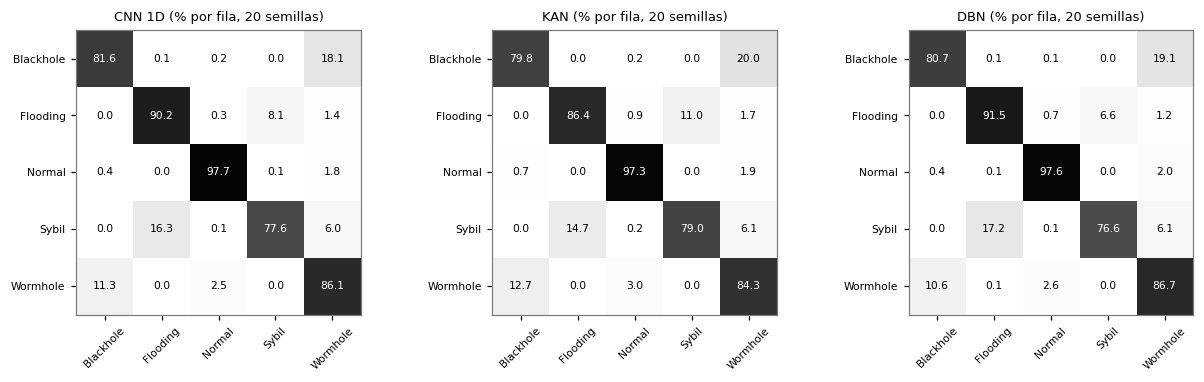

In [49]:
CATEGORIAS = {"Confusión Blackhole–Wormhole": lambda v, p: ((v == 0) & (p == 4)) | ((v == 4) & (p == 0)), "Ataque predicho como Normal": lambda v, p: (v != 2) & (p == 2),
              "Normal predicho como ataque": lambda v, p: (v == 2) & (p != 2)}
def categorias_error(v, p):
    error = v != p
    otras = error.copy()
    salida = {}
    for nombre, f in CATEGORIAS.items():
        salida[nombre] = f(v, p) & error
        otras &= ~salida[nombre]
    salida["Otras confusiones entre ataques"] = otras
    return salida, error
y_pru = y[ID_PRU]
b_pru = bloques[ID_PRU]
taxonomia, errores_por_modelo = [], {}
for m in TOP3 + ["LightGBM"]:
    r = next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0])
    p = AN.prob(r, "eva").argmax(1)
    cats, error = categorias_error(y_pru, p)
    errores_por_modelo[m] = error
    for nombre, mascara in cats.items():
        boot = E.bootstrap_bloques(lambda ix: mascara[ix].sum() / max(error[ix].sum(), 1), b_pru, repeticiones=2000)
        taxonomia.append({"Modelo": m, "Categoría": nombre, "Errores": int(mascara.sum()), "% de los errores": 100 * mascara.sum() / error.sum(), "IC 95 % por bloques": intervalo(100 * np.array(E.ic_percentil(boot)), 1)})
tabla(pd.DataFrame(taxonomia), {"% de los errores": "{:.1f}"})
todos = np.mean([errores_por_modelo[m] for m in TOP3], 0)
compartidos = float((todos == 1).sum() / max((todos > 0).sum(), 1))
correlacion = pd.DataFrame(np.corrcoef([errores_por_modelo[m].astype(float) for m in errores_por_modelo]), index=list(errores_por_modelo), columns=list(errores_por_modelo))
tabla(correlacion.reset_index(names="Correlación de los errores (φ)"), {c: "{:.3f}" for c in correlacion.columns})
promedio_top3 = np.mean([AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == SEMILLAS[0]), "eva") for m in TOP3], 0)
f1_ensamble = E.f1_macro_rapido(y_pru, promedio_top3.argmax(1))
oraculo = 1 - (todos == 1).mean()
tax = pd.DataFrame(taxonomia)
dominante = tax.loc[tax.groupby("Modelo")["% de los errores"].idxmax()].set_index("Modelo")
mejor_ind = max(METRICAS.loc[(METRICAS["modelo"] == m) & (METRICAS["semilla"] == SEMILLAS[0]), "prueba F1 macro"].iloc[0] for m in TOP3)
phi = correlacion.loc[TOP3, TOP3].to_numpy()[np.triu_indices(len(TOP3), 1)]
phi_lgbm = correlacion.loc[TOP3, "LightGBM"].to_numpy()
NOMBRE_CAT = {"Confusión Blackhole–Wormhole": "la confusión entre Blackhole y Wormhole", "Otras confusiones entre ataques": "las demás confusiones entre ataques",
              "Ataque predicho como Normal": "los ataques predichos como Normal", "Normal predicho como ataque": "los flujos normales predichos como ataque"}
partes_dom = []
for cat, sub_d in dominante.groupby("Categoría"):
    pct_txt = num(sub_d["% de los errores"].iloc[0], 1) if len(sub_d) == 1 else f"{num(sub_d['% de los errores'].min(), 1)} % a {num(sub_d['% de los errores'].max(), 1)}"
    partes_dom.append(f"{NOMBRE_CAT.get(cat, cat)} en {enumerar(sub_d.index.tolist())} ({pct_txt} % de sus errores)")
concentrados = compartidos >= 0.5
gana_comb = f1_ensamble - mejor_ind > DELTA
if concentrados and not gana_comb:
    lectura_err = "Esto quiere decir que los errores se concentran en los mismos flujos, de modo que, como advierte la sección 12.3 del enunciado, el benchmark mide sobre todo la dificultad de esos casos y no diferencias de arquitectura. En ese sentido, combinar modelos gana menos que δ, porque se equivocan juntos."
elif concentrados:
    lectura_err = "Esto quiere decir que buena parte de los errores se concentra en los mismos flujos, pero el promedio de probabilidades aún gana más que δ, porque corrige los flujos en que solo uno de los tres se equivoca."
elif gana_comb:
    lectura_err = "Esto quiere decir que los errores no se concentran en los mismos flujos: cada modelo falla casos distintos, y por eso promediar sus probabilidades gana más que δ."
else:
    lectura_err = "Esto quiere decir que los errores no se concentran en los mismos flujos, pero promediar las probabilidades gana menos que δ: en los flujos en que discrepan, el promedio no siempre favorece a la clase correcta, como muestra la distancia entre el ensamble y el oráculo."
interpretar(f'''**Interpretación.** En los tres mejores modelos y en LightGBM, la categoría que reúne más errores es {enumerar(partes_dom)}. De los flujos en que se equivoca al menos uno de los tres mejores, el {num(100 * compartidos, 1)} % lo fallan los tres; la correlación de sus errores va de {num(phi.min(), 3)} a {num(phi.max(), 3)}, y con LightGBM, de {num(phi_lgbm.min(), 3)} a {num(phi_lgbm.max(), 3)}, y el promedio de sus probabilidades obtiene un F1 macro de {num(f1_ensamble, 4)}, frente a {num(mejor_ind, 4)} del mejor de ellos con la misma semilla; un oráculo que eligiera siempre al que acierta llegaría a una exactitud de {num(oraculo, 4)}.

{lectura_err}

Por ello, se recomienda que el modelo original del Entregable 3 ataque {"la confusión entre Blackhole y Wormhole, que domina en " + enumerar(dominante.index[dominante["Categoría"] == "Confusión Blackhole–Wormhole"].tolist()) + " y coincide con la limitación del paper guía (sección 5)" if "Confusión Blackhole–Wormhole" in set(dominante["Categoría"]) else "la categoría dominante"}{", en lugar de buscar más capacidad o combinar arquitecturas" if f1_ensamble - mejor_ind <= DELTA else ", y que evalúe la combinación de arquitecturas como línea base"}.''')
fig, ejes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for eje, m in zip(ejes, TOP3):
    conf_total = sum(np.bincount(K * y_pru + AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva").argmax(1), minlength=K * K).reshape(K, K) for s in SEMILLAS)
    normalizada = conf_total / conf_total.sum(1, keepdims=True)
    eje.imshow(normalizada, vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            eje.text(j, i, f"{100 * normalizada[i, j]:.1f}", ha="center", va="center", fontsize=7, color="white" if normalizada[i, j] > 0.5 else NEGRO)
    eje.set_xticks(range(K), CLASES, rotation=45, fontsize=7)
    eje.set_yticks(range(K), CLASES, fontsize=7)
    eje.set_title(f"{m} (% por fila, {R} semillas)", fontsize=8.5)
    eje.grid(False)
plt.tight_layout()
plt.show()

Modelo,F1 Blackhole,F1 Flooding,F1 Normal,F1 Sybil,F1 Wormhole,Muy cortos,Cortos,Medianos,Largos,Con puerto 654,Sin puerto 654,Sin casi duplicado,Con casi duplicado
DNN,"0,8300","0,8082","0,9736","0,8595","0,8170","0,7475","0,8140","0,8353","0,7596","0,9940","0,8274","0,8580","0,7894"
CNN 1D,"0,8374","0,8055","0,9734","0,8548","0,8211","0,7737","0,8137","0,8278","0,7693","0,9934","0,8291","0,8588","0,7866"
LSTM,"0,8167","0,7442","0,9535","0,8238","0,8043","0,6963","0,7688","0,7885","0,7216","0,9846","0,7989","0,8287","0,7564"
CNN-LSTM,"0,8568","0,7942","0,9702","0,8478","0,8436","0,7657","0,8333","0,8128","0,7607","0,9936","0,8373","0,8631","0,7789"
Autoencoder,"0,8329","0,8085","0,9691","0,8636","0,8214","0,7725","0,8221","0,8365","0,7629","0,9908","0,8303","0,8595","0,7817"
RNN,"0,8074","0,7892","0,9551","0,8525","0,7813","0,7331","0,7844","0,7957","0,7482","0,9886","0,8024","0,8371","0,7582"
Transformer,"0,8377","0,8017","0,9698","0,8523","0,8268","0,7544","0,8263","0,8135","0,7581","0,9892","0,8300","0,8582","0,7705"
BiLSTM,"0,8327","0,7764","0,9618","0,8397","0,8179","0,7571","0,8075","0,8030","0,7411","0,9872","0,8176","0,8462","0,7636"
ResNet,"0,8123","0,8051","0,9655","0,8631","0,8087","0,7640","0,8118","0,8209","0,7531","0,9874","0,8202","0,8513","0,7553"
GRU,"0,8110","0,8057","0,9619","0,8607","0,7978","0,7549","0,8029","0,8186","0,7480","0,9902","0,8145","0,8476","0,7798"


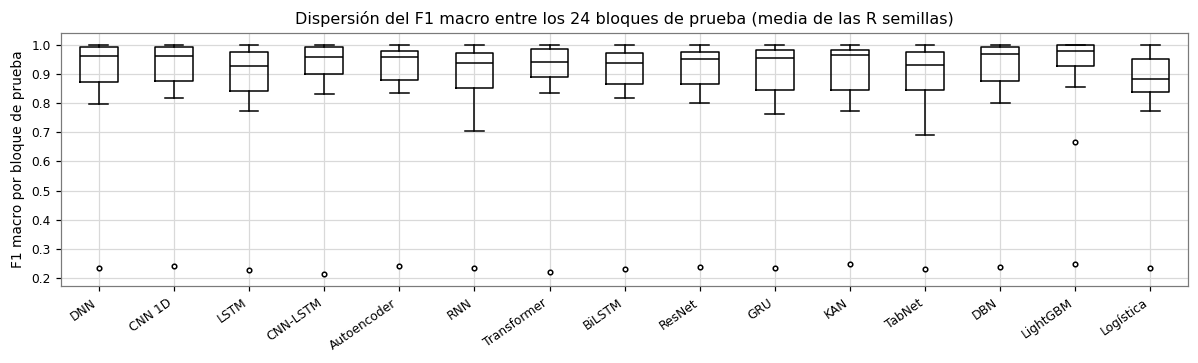

**Interpretación.** Promediando los 13 modelos profundos, la clase más difícil es Flooding, con F1 de 0,793, y la más fácil, Normal, con 0,965. La exactitud en los flujos con el puerto 654 difiere de la de los flujos sin él entre 0,156 y 0,194 según el modelo, y los flujos de prueba con un casi duplicado en entrenamiento obtienen un F1 macro menor que los demás, entre 0,068 y 0,096. Entre los 24 bloques de prueba, el rango intercuartílico del F1 macro va de 0,073 a 0,137.

Es decir, el desempeño depende más de la serie y de la clase que del modelo: la dispersión entre bloques es de 12 veces δ en mediana, y la diferencia por el puerto 654 indica que el modelo aprovecha la configuración del escenario que el puerto delata, un atajo indirecto a través de los atributos de tráfico. Así mismo, los casi duplicados son pocos (1,8 % de la prueba), de modo que su efecto sobre el F1 global es acotado.

Por lo anterior, conviene leer las comparaciones de la sección 6 como pareadas sobre las mismas series y no como estimaciones del desempeño en un enjambre nuevo, y declarar la dependencia de la serie como amenaza a la validez externa.

In [50]:
from sklearn.metrics import f1_score

cortes_flujo = np.quantile(H["tx_packets"][ID_ENT], [0.25, 0.5, 0.75])
banda = np.digitize(H["tx_packets"][ID_PRU], cortes_flujo)
puerto654 = datos["SrcPort"].to_numpy()[ID_PRU] == 654
casi_dup = np.load(ANALISIS / "prueba_con_casi_duplicado.npy")
segmentos = []
for m in ORDEN:
    if m == "Trivial":
        continue
    preds = [AN.prob(next(x for x in DEF if x["modelo"] == m and x["semilla"] == s), "eva").argmax(1) for s in SEMILLAS]
    fila = {"Modelo": m}
    por_clase = np.mean([f1_score(y_pru, p, average=None, labels=range(K)) for p in preds], 0)
    for c in range(K):
        fila[f"F1 {CLASES[c]}"] = por_clase[c]
    for b, nombre in enumerate(["Muy cortos", "Cortos", "Medianos", "Largos"]):
        fila[nombre] = np.mean([E.f1_macro_rapido(y_pru[banda == b], p[banda == b]) for p in preds])
    fila["Con puerto 654"] = np.mean([(p[puerto654] == y_pru[puerto654]).mean() for p in preds])
    fila["Sin puerto 654"] = np.mean([(p[~puerto654] == y_pru[~puerto654]).mean() for p in preds])
    fila["Sin casi duplicado"] = np.mean([E.f1_macro_rapido(y_pru[~casi_dup], p[~casi_dup]) for p in preds])
    fila["Con casi duplicado"] = np.mean([E.f1_macro_rapido(y_pru[casi_dup], p[casi_dup]) for p in preds])
    segmentos.append(fila)
SEGMENTOS = pd.DataFrame(segmentos)
tabla(SEGMENTOS, {c: "{:.4f}" for c in SEGMENTOS.columns if c != "Modelo"})
f1_bloque = {m: np.array([[AN.f1_desde_conteos(CONF_BLOQUES[f"{i}|eva"][b]) for b in range(NB_PRU)] for i in METRICAS.loc[METRICAS["modelo"] == m, "id"]]).mean(0) for m in ORDEN if m != "Trivial"}
fig, eje = plt.subplots(figsize=(11, 3.4))
eje.boxplot([f1_bloque[m] for m in f1_bloque], labels=list(f1_bloque), medianprops=dict(color=NEGRO), flierprops=dict(marker="o", markersize=3, markerfacecolor="white"))
eje.set_ylabel("F1 macro por bloque de prueba")
eje.set_title(f"Dispersión del F1 macro entre los {NB_PRU} bloques de prueba (media de las R semillas)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()
sg = SEGMENTOS.set_index("Modelo")
clases_f1 = sg[[f"F1 {c}" for c in CLASES]].loc[PROFUNDOS].mean()
dif_puerto = (sg["Con puerto 654"] - sg["Sin puerto 654"]).loc[PROFUNDOS]
dif_casi = (sg["Con casi duplicado"] - sg["Sin casi duplicado"]).loc[PROFUNDOS]
iqr = {m: np.subtract(*np.percentile(v, [75, 25])) for m, v in f1_bloque.items()}
interpretar(f'''**Interpretación.** Promediando los 13 modelos profundos, la clase más difícil es {clases_f1.idxmin().replace("F1 ", "")}, con F1 de {num(clases_f1.min(), 3)}, y la más fácil, {clases_f1.idxmax().replace("F1 ", "")}, con {num(clases_f1.max(), 3)}. La exactitud en los flujos con el puerto 654 difiere de la de los flujos sin él entre {num(dif_puerto.min(), 3)} y {num(dif_puerto.max(), 3)} según el modelo, y los flujos de prueba con un casi duplicado en entrenamiento obtienen un F1 macro {f"mayor que los demás, entre {num(dif_casi.min(), 3)} y {num(dif_casi.max(), 3)}" if (dif_casi > 0).all() else f"menor que los demás, entre {num(-dif_casi.max(), 3)} y {num(-dif_casi.min(), 3)}" if (dif_casi < 0).all() else f"que difiere del de los demás entre {num(dif_casi.min(), 3)} y {num(dif_casi.max(), 3)} según el modelo"}. Entre los {NB_PRU} bloques de prueba, el rango intercuartílico del F1 macro va de {num(min(iqr.values()), 3)} a {num(max(iqr.values()), 3)}.

Es decir, {"el desempeño depende más de la serie y de la clase que del modelo: la dispersión entre bloques es de " + num(np.median(list(iqr.values())) / DELTA, 0) + " veces δ en mediana" if np.median(list(iqr.values())) > 2 * DELTA else "la dispersión entre bloques es pequeña frente a δ"}, y la diferencia por el puerto 654 indica {"que el modelo aprovecha la configuración del escenario que el puerto delata, un atajo indirecto a través de los atributos de tráfico" if dif_puerto.abs().max() > 2 * DELTA else "que el puerto, excluido de las entradas, no deja un atajo apreciable en los atributos de tráfico"}. Así mismo, los casi duplicados son pocos ({num(100 * casi_dup.mean(), 1)} % de la prueba), de modo que su efecto sobre el F1 global es acotado.

Por lo anterior, conviene leer las comparaciones de la sección 6 como pareadas sobre las mismas series y no como estimaciones del desempeño en un enjambre nuevo, y declarar la dependencia de la serie como amenaza a la validez externa.''')

(sec-4-6)=
## 4.6 Robustez, interpretabilidad y ablación

**Robustez.** Cada modelo, con sus primeras cinco semillas, se evalúa sobre la prueba con tres perturbaciones controladas y al menos tres niveles de severidad, definidas en el preregistro: ruido gaussiano en la escala estandarizada, atributos faltantes imputados con la media de entrenamiento y escalamiento multiplicativo de los atributos crudos, que simula una deriva en la medición. El índice de robustez es el área bajo la curva de degradación del F1 macro, normalizada por el F1 sin perturbar y por el rango de severidades, de modo que 1 indica que el modelo no se degrada.

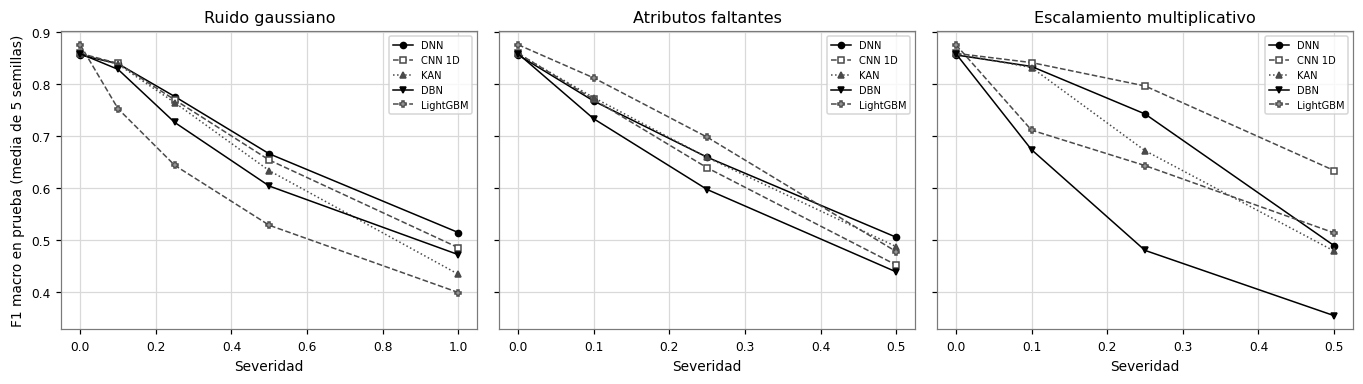

Modelo,Ruido gaussiano,Atributos faltantes,Escalamiento multiplicativo,Índice medio
DNN,"0,7957","0,7797","0,8333","0,8029"
CNN 1D,"0,7779","0,7532","0,9000","0,8104"
LSTM,"0,8332","0,7807","0,9071","0,8403"
CNN-LSTM,"0,7342","0,7538","0,8160","0,7680"
Autoencoder,"0,7998","0,7929","0,7762","0,7896"
RNN,"0,7618","0,7515","0,9004","0,8046"
Transformer,"0,7708","0,7505","0,8384","0,7866"
BiLSTM,"0,7691","0,7467","0,8933","0,8031"
ResNet,"0,7981","0,7709","0,8751","0,8147"
GRU,"0,7471","0,7257","0,8570","0,7766"


**Interpretación.** La perturbación que más degrada a los modelos es ruido gaussiano, con un índice medio de 0,740. El modelo más robusto en promedio es LSTM (0,840) y el menos robusto, Logística (0,409); LightGBM obtiene 0,725, con 0,787 ante atributos faltantes, frente a una mediana de 0,753 en los modelos profundos.

Esto significa que la robustez no sigue el orden del desempeño sin perturbar (ρ de Spearman entre el F1 limpio y el índice medio = -0,31, p = 0,254), de modo que es un eje propio de la comparación, como pide la discusión del enunciado. Hay que tener en cuenta que imputar con la media de entrenamiento, que es 0 tras estandarizar, deja el valor en el centro de la distribución, lo que favorece a los modelos que no dependen de un solo atributo.

Por tal motivo, la tabla principal de la sección {ref}`6.1 <sec-6-1>` incluye el índice medio de robustez, y la fragilidad ante ruido gaussiano queda como criterio para el modelo original del Entregable 3, junto con la tokenización por atributo de la búsqueda transversal (sección {ref}`3.1 <sec-3-1>`).

In [51]:
PERT = AN.perturbaciones()
limpio = PERT[PERT["perturbacion"] == "Sin perturbar"].groupby("modelo")["f1"].mean()
indices_rob = {}
fig, ejes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True)
for eje, tipo in zip(ejes, AN.NIVELES):
    for j, m in enumerate([x for x in ORDEN if x != "Trivial"]):
        sub_p = PERT[(PERT["perturbacion"] == tipo) & (PERT["modelo"] == m)].groupby("nivel")["f1"].mean()
        niveles = np.r_[0.0, sub_p.index.to_numpy()]
        curva = np.r_[limpio[m], sub_p.to_numpy()]
        indices_rob[(m, tipo)] = float(np.trapezoid(curva, niveles) / (limpio[m] * (niveles[-1] - niveles[0])))
        if m in TOP3 + ["LightGBM", "DNN"]:
            eje.plot(niveles, curva, ls=LINEAS[j % 4], marker=MARCADORES[j % 8], ms=4, color=[NEGRO, GRIS_OSCURO, GRIS_MEDIO][j % 3], mfc="white" if j % 2 else None, lw=1, label=m)
    eje.set(title=tipo, xlabel="Severidad")
    eje.legend(fontsize=6.5)
ejes[0].set_ylabel("F1 macro en prueba (media de 5 semillas)")
plt.tight_layout()
plt.show()
ROBUSTEZ = pd.DataFrame({tipo: {m: indices_rob[(m, tipo)] for m in limpio.index} for tipo in AN.NIVELES})
ROBUSTEZ["Índice medio"] = ROBUSTEZ.mean(1)
tabla(ROBUSTEZ.loc[[m for m in ORDEN if m in ROBUSTEZ.index]].reset_index(names="Modelo"), {c: "{:.4f}" for c in ROBUSTEZ.columns})
peor_pert = ROBUSTEZ[list(AN.NIVELES)].mean().idxmin()
mas_rob = ROBUSTEZ["Índice medio"].idxmax()
menos_rob = ROBUSTEZ["Índice medio"].idxmin()
rho_rob = stats.spearmanr(limpio.loc[ROBUSTEZ.index], ROBUSTEZ["Índice medio"])
interpretar(f'''**Interpretación.** La perturbación que más degrada a los modelos es {peor_pert.lower()}, con un índice medio de {num(ROBUSTEZ[peor_pert].mean(), 3)}. El modelo más robusto en promedio es {mas_rob} ({num(ROBUSTEZ.loc[mas_rob, "Índice medio"], 3)}) y el menos robusto, {menos_rob} ({num(ROBUSTEZ.loc[menos_rob, "Índice medio"], 3)}); LightGBM obtiene {num(ROBUSTEZ.loc["LightGBM", "Índice medio"], 3)}, con {num(ROBUSTEZ.loc["LightGBM", "Atributos faltantes"], 3)} ante atributos faltantes, frente a una mediana de {num(ROBUSTEZ.loc[PROFUNDOS, "Atributos faltantes"].median(), 3)} en los modelos profundos.

Esto significa que la robustez {"no sigue el orden del desempeño sin perturbar" if not (rho_rob.pvalue < ALFA and rho_rob.statistic > 0) else "acompaña al desempeño sin perturbar"} (ρ de Spearman entre el F1 limpio y el índice medio = {num(rho_rob.statistic, 2)}, {valor_p(rho_rob.pvalue)}), de modo que {"es un eje propio de la comparación, como pide la discusión del enunciado" if not (rho_rob.pvalue < ALFA and rho_rob.statistic > 0) else "los mejores modelos son también los más robustos"}. Hay que tener en cuenta que imputar con la media de entrenamiento, que es 0 tras estandarizar, deja el valor en el centro de la distribución, lo que favorece a los modelos que no dependen de un solo atributo.

Por tal motivo, la tabla principal de la sección 6.1 incluye el índice medio de robustez, y la fragilidad ante {peor_pert.lower()} queda como criterio para el modelo original del Entregable 3, junto con la tokenización por atributo de la búsqueda transversal (sección 3.1).''')

**Interpretabilidad.** A los tres mejores modelos por validación se aplican gradientes integrados (Sundararajan et al., 2017), $IG_j(\mathbf{x}) = (x_j - x'_j) \int_0^1 \frac{\partial f_c(\mathbf{x}' + \alpha(\mathbf{x} - \mathbf{x}'))}{\partial x_j} d\alpha$, con la base $\mathbf{x}'$ en la media de entrenamiento y 32 pasos, sobre 1500 flujos de prueba estratificados por clase y cinco semillas. La **fidelidad** se verifica con una prueba de borrado: se anulan los atributos en el orden de su atribución y se compara la caída de la probabilidad de la clase predicha con la de un orden aleatorio; una explicación fiel produce una caída más rápida. La **estabilidad** se mide con la correlación de Spearman entre los vectores de importancia de cada par de semillas.

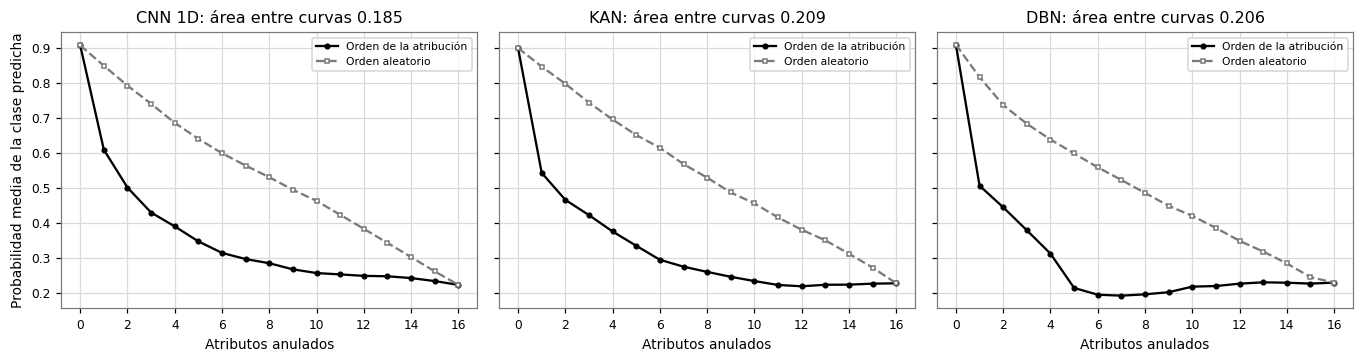

Modelo,Estabilidad media (ρ),Estabilidad mínima (ρ),Área entre curvas,Tres atributos más importantes
CNN 1D,"0,797","0,706","0,185","PacketDropRate, MeanPacketSize, Throughput/Kbps"
KAN,"0,687","0,538","0,209","PacketDropRate, MeanPacketSize, FlowDuration/s"
DBN,"0,977","0,947","0,206","MeanPacketSize, Throughput/Kbps, PacketDropRate"


Atributo,CNN 1D,KAN,DBN
PacketDropRate,"0,121","0,156","0,103"
MeanPacketSize,"0,121","0,115","0,190"
Throughput/Kbps,"0,092","0,073","0,119"
TxBytes,"0,075","0,049","0,068"
FlowDuration/s,"0,075","0,077","0,050"
AverageHopCount,"0,065","0,064","0,029"
TxPackets,"0,058","0,062","0,062"
TxByteRate/s,"0,055","0,074","0,096"
LostPackets,"0,050","0,042","0,048"
RxPacketRate/s,"0,050","0,061","0,057"


**Interpretación.** La estabilidad de las atribuciones entre semillas, medida con la ρ de Spearman media, va de 0,687 a 0,977 en los tres mejores modelos, con un mínimo por par de 0,538. En la prueba de borrado, el área entre la curva aleatoria y la de la atribución es positiva en los tres modelos, de 0,185 a 0,209. Los tres atributos más importantes son, en CNN 1D, PacketDropRate, MeanPacketSize y Throughput/Kbps; en KAN, PacketDropRate, MeanPacketSize y FlowDuration/s; en DBN, MeanPacketSize, Throughput/Kbps y PacketDropRate.

Lo anterior indica que las explicaciones no son a la vez fieles y estables en todos los modelos: en KAN, la estabilidad media entre semillas no pasa de 0,7, de modo que el orden de los atributos cambia según la semilla; en CNN 1D y DBN, en cambio, son fieles y estables. Por eso, las atribuciones de KAN no deben leerse como evidencia del mecanismo. En cuanto al dominio, la coherencia se evalúa frente a lo que distingue a los ataques: Flooding eleva las tasas de envío, Sybil multiplica las identidades y altera el volumen, y Blackhole y Wormhole cambian el número de saltos y la entrega de paquetes; una atribución concentrada en atributos de volumen explicaría bien Flooding, pero no la frontera entre los dos ataques de enrutamiento.

Por ello, se recomienda usar estas atribuciones como diagnóstico y no como explicación causal, y contrastarlas en el Entregable 3 con atribuciones calculadas solo sobre los flujos de Blackhole y Wormhole.

In [52]:
ATR = AN.atribuciones(TOP3)
filas_i, estabilidad = [], {}
fig, ejes = plt.subplots(1, 3, figsize=(12.5, 3.4), sharey=True)
for eje, m in zip(ejes, TOP3):
    imp = ATR[f"{m}|importancia"]
    imp_n = imp / imp.sum(1, keepdims=True)
    rhos = [stats.spearmanr(imp[a], imp[b]).statistic for a in range(len(imp)) for b in range(a + 1, len(imp))]
    estabilidad[m] = (np.mean(rhos), np.min(rhos))
    borr, alea = ATR[f"{m}|borrado"].mean(0), ATR[f"{m}|aleatorio"].mean(0)
    k = np.arange(len(borr))
    eje.plot(k, borr, color=NEGRO, marker="o", ms=3, label="Orden de la atribución")
    eje.plot(k, alea, color=GRIS_MEDIO, ls="--", marker="s", ms=3, mfc="white", label="Orden aleatorio")
    aopc = float((alea - borr).mean())
    eje.set(title=f"{m}: área entre curvas {aopc:.3f}", xlabel="Atributos anulados")
    eje.legend(fontsize=7)
    orden_imp = np.argsort(-imp_n.mean(0))
    filas_i.append({"Modelo": m, "Estabilidad media (ρ)": estabilidad[m][0], "Estabilidad mínima (ρ)": estabilidad[m][1], "Área entre curvas": aopc,
                    "Tres atributos más importantes": ", ".join(ATRIBUTOS[j] for j in orden_imp[:3])})
ejes[0].set_ylabel("Probabilidad media de la clase predicha")
plt.tight_layout()
plt.show()
INTERP = pd.DataFrame(filas_i)
tabla(INTERP, {"Estabilidad media (ρ)": "{:.3f}", "Estabilidad mínima (ρ)": "{:.3f}", "Área entre curvas": "{:.3f}"})
importancia_tabla = pd.DataFrame({m: (ATR[f"{m}|importancia"] / ATR[f"{m}|importancia"].sum(1, keepdims=True)).mean(0) for m in TOP3}, index=ATRIBUTOS)
tabla(importancia_tabla.sort_values(TOP3[0], ascending=False).reset_index(names="Atributo"), {m: "{:.3f}" for m in TOP3})
inestables = INTERP.loc[INTERP["Estabilidad media (ρ)"] <= 0.7, "Modelo"].tolist()
infieles = INTERP.loc[INTERP["Área entre curvas"] <= 0, "Modelo"].tolist()
fiables = [m for m in INTERP["Modelo"] if m not in inestables + infieles]
lectura_interp = ("las explicaciones no son a la vez fieles y estables en todos los modelos"
                  + (f": en {enumerar(inestables)}, la estabilidad media entre semillas no pasa de 0,7, de modo que el orden de los atributos cambia según la semilla" if inestables else "")
                  + (f"{'; y en ' if inestables else ': en '}{enumerar(infieles)}, anular los atributos señalados no reduce la confianza más que un orden aleatorio" if infieles else "")
                  + (f"; en {enumerar(fiables)}, en cambio, son fieles y estables. Por eso, las atribuciones de {enumerar(inestables + infieles)} no deben leerse como evidencia del mecanismo" if fiables
                     else ", de modo que no deben leerse como evidencia del mecanismo"))
interpretar(f'''**Interpretación.** La estabilidad de las atribuciones entre semillas, medida con la ρ de Spearman media, va de {num(INTERP["Estabilidad media (ρ)"].min(), 3)} a {num(INTERP["Estabilidad media (ρ)"].max(), 3)} en los tres mejores modelos, con un mínimo por par de {num(INTERP["Estabilidad mínima (ρ)"].min(), 3)}. En la prueba de borrado, el área entre la curva aleatoria y la de la atribución es {"positiva en los tres modelos" if (INTERP["Área entre curvas"] > 0).all() else "positiva solo en " + enumerar(INTERP.loc[INTERP["Área entre curvas"] > 0, "Modelo"])}, de {num(INTERP["Área entre curvas"].min(), 3)} a {num(INTERP["Área entre curvas"].max(), 3)}. Los tres atributos más importantes son, {"; ".join(f"en {f['Modelo']}, {enumerar(f['Tres atributos más importantes'].split(', '))}" for _, f in INTERP.iterrows())}.

Lo anterior indica que {"las explicaciones son fieles, porque anular primero los atributos que señalan reduce la confianza más rápido que un orden aleatorio, y estables, porque se repiten entre semillas" if (INTERP["Área entre curvas"] > 0).all() and INTERP["Estabilidad media (ρ)"].min() > 0.7 else lectura_interp}. En cuanto al dominio, la coherencia se evalúa frente a lo que distingue a los ataques: Flooding eleva las tasas de envío, Sybil multiplica las identidades y altera el volumen, y Blackhole y Wormhole cambian el número de saltos y la entrega de paquetes; una atribución concentrada en atributos de volumen explicaría bien Flooding, pero no la frontera entre los dos ataques de enrutamiento.

Por ello, se recomienda usar estas atribuciones como diagnóstico y no como explicación causal, y contrastarlas en el Entregable 3 con atribuciones calculadas solo sobre los flujos de Blackhole y Wormhole.''')

**Ablación.** Sobre el mejor modelo por validación se aíslan tres componentes del pipeline común, con las mismas R semillas: la ponderación de la pérdida por clase, la transformación $\log(1 + x)$ y el *dropout*. Cada variante cambia un solo componente, y la diferencia con el modelo completo se prueba con la *t* pareada, Wilcoxon y TOST sobre las semillas.

In [53]:
abl = RES.tabla_fase("ablacion")
completo = METRICAS[METRICAS["modelo"] == MEJOR_DL].set_index("semilla")["prueba F1 macro"]
filas_a = []
for variante in sorted(abl["variante_nombre"].unique()):
    sub_a = abl[abl["variante_nombre"] == variante].set_index("semilla")
    comunes = sorted(set(sub_a.index) & set(completo.index))
    r_ab = E.comparar_par(sub_a.loc[comunes, "f1_eva"].to_numpy(), completo.loc[comunes].to_numpy())
    filas_a.append({"Variante": variante, "Semillas": len(comunes), "F1 macro de prueba": sub_a.loc[comunes, "f1_eva"].mean(), "Diferencia con el completo": r_ab["Diferencia media"],
                    "IC 95 %": intervalo(r_ab["IC 95 % t"] if r_ab["Shapiro-Wilk p"] >= ALFA else r_ab["IC 95 % bootstrap"]), "p t": r_ab["p t pareada"], "p Wilcoxon": r_ab["p Wilcoxon"],
                    "p TOST": r_ab["p TOST"], "d de Cohen": r_ab["d de Cohen pareada"]})
ABLACION = pd.DataFrame(filas_a)
ARTICULO_ABL = {"dropout": ("el *dropout*", "al *dropout*"), "ponderación de clases": ("la ponderación de clases", "a la ponderación de clases"), "log(1 + x)": ("la transformación log(1 + x)", "a la transformación log(1 + x)")}
val_completo = np.mean([r["f1_val"] for r in DEF if r["modelo"] == MEJOR_DL])
ABLACION.insert(4, "Diferencia en validación", [abl.loc[abl["variante_nombre"] == v_, "f1_val"].mean() - val_completo for v_ in ABLACION["Variante"]])
ABLACION[["p t Holm", "p Wilcoxon Holm"]] = np.column_stack([E.holm(ABLACION["p t"]), E.holm(ABLACION["p Wilcoxon"])])
tabla(ABLACION, {"F1 macro de prueba": "{:.4f}", "Diferencia con el completo": "{:+.4f}", "Diferencia en validación": "{:+.4f}", "p t": "{:.4f}", "p Wilcoxon": "{:.4f}", "p TOST": "{:.4f}", "d de Cohen": "{:.2f}", "p t Holm": "{:.4f}", "p Wilcoxon Holm": "{:.4f}"})
sig_abl = ABLACION[(ABLACION["p t Holm"] < ALFA) & (ABLACION["p Wilcoxon Holm"] < ALFA)]
indicio = ABLACION[(ABLACION["Diferencia con el completo"].abs() > DELTA) & ((ABLACION["p t Holm"] < ALFA) | (ABLACION["p Wilcoxon Holm"] < ALFA)) & ~ABLACION.index.isin(sig_abl.index)]
if (sig_abl["Diferencia con el completo"].abs() > DELTA).any():
    lectura_abl = "el componente con efecto relevante es " + enumerar(sig_abl.loc[sig_abl["Diferencia con el completo"].abs() > DELTA, "Variante"])
    decision_abl = "revisar en el Entregable 3 el componente con efecto relevante"
elif len(indicio):
    f_i = indicio.iloc[0]
    lectura_abl = (f"ningún componente cumple el criterio de las dos pruebas, pero «{f_i['Variante']}» se acerca: su diferencia supera δ, su IC excluye el cero y la "
                   + ("*t* pareada la declara significativa tras Holm (p = " + num(f_i["p t Holm"], 3) + "), aunque Wilcoxon no (p = " + num(f_i["p Wilcoxon Holm"], 3) + ")" if f_i["p t Holm"] < ALFA
                      else "prueba de Wilcoxon la declara significativa tras Holm (p = " + num(f_i["p Wilcoxon Holm"], 3) + "), aunque la *t* no (p = " + num(f_i["p t Holm"], 3) + ")")
                   + f"; en validación, el mismo cambio mueve el F1 en {num(f_i['Diferencia en validación'], 4)}, unas {num(abs(f_i['Diferencia en validación']) / DELTA, 1)} veces δ. Es decir, es el componente del pipeline con más evidencia de aportar")
    otras = [v_ for v_ in ABLACION.loc[ABLACION["p TOST"] < ALFA, "Variante"]]
    decision_abl = ("conservar el pipeline común, que incluye ese componente" + (", y no atribuir el desempeño " + " ni ".join(ARTICULO_ABL.get(v_.replace("sin ", "", 1), (v_, v_))[1] for v_ in otras) + ", que resultan equivalentes a no usarlos dentro de ±δ" if otras else ""))
else:
    lectura_abl = "ningún componente del pipeline común cambia el desempeño en una magnitud mayor que δ con evidencia estadística"
    decision_abl = "no atribuir el desempeño del mejor modelo a la ponderación, la transformación ni el dropout"
interpretar(f'''**Interpretación.** Sobre {MEJOR_DL}, la variante con el mayor cambio es «{ABLACION.loc[ABLACION["Diferencia con el completo"].abs().idxmax(), "Variante"]}», con una diferencia de {num(ABLACION["Diferencia con el completo"].abs().max() * np.sign(ABLACION.loc[ABLACION["Diferencia con el completo"].abs().idxmax(), "Diferencia con el completo"]), 4)} en F1 macro de prueba. {"Las diferencias significativas tras Holm, en ambas pruebas, son las de " + enumerar("«" + sig_abl["Variante"] + "»") if len(sig_abl) else "Ninguna diferencia es significativa tras Holm con las dos pruebas a la vez"}, y {"TOST declara equivalentes al modelo completo, dentro de ±δ, las variantes " + enumerar("«" + ABLACION.loc[ABLACION["p TOST"] < ALFA, "Variante"] + "»") if (ABLACION["p TOST"] < ALFA).any() else "TOST no declara equivalente al modelo completo ninguna variante"}.

Esto significa que {lectura_abl}. Hay que tener en cuenta que la ablación aísla componentes del pipeline y no de la arquitectura, porque el diseño del modelo viene de la literatura.

En consecuencia, se decide {decision_abl}.''')

Variante,Semillas,F1 macro de prueba,Diferencia con el completo,Diferencia en validación,IC 95 %,p t,p Wilcoxon,p TOST,d de Cohen,p t Holm,p Wilcoxon Holm
sin dropout,20,"0,8541","-0,0043","-0,0019","[-0,0085; -0,0006]","0,0508","0,0696","0,0064","-0,47","0,1016","0,1392"
sin log(1 + x),20,"0,8457","-0,0127","-0,0416","[-0,0225; -0,0029]","0,0135","0,0441","0,7162","-0,61","0,0404","0,1322"
sin ponderación de clases,20,"0,8613","+0,0029","+0,0022","[0,0003; 0,0060]","0,0684","0,0897","0,0001","0,43","0,1016","0,1392"


**Interpretación.** Sobre CNN 1D, la variante con el mayor cambio es «sin log(1 + x)», con una diferencia de -0,0127 en F1 macro de prueba. Ninguna diferencia es significativa tras Holm con las dos pruebas a la vez, y TOST declara equivalentes al modelo completo, dentro de ±δ, las variantes «sin dropout» y «sin ponderación de clases».

Esto significa que ningún componente cumple el criterio de las dos pruebas, pero «sin log(1 + x)» se acerca: su diferencia supera δ, su IC excluye el cero y la *t* pareada la declara significativa tras Holm (p = 0,040), aunque Wilcoxon no (p = 0,132); en validación, el mismo cambio mueve el F1 en -0,0416, unas 4,2 veces δ. Es decir, es el componente del pipeline con más evidencia de aportar. Hay que tener en cuenta que la ablación aísla componentes del pipeline y no de la arquitectura, porque el diseño del modelo viene de la literatura.

En consecuencia, se decide conservar el pipeline común, que incluye ese componente, y no atribuir el desempeño al *dropout* ni a la ponderación de clases, que resultan equivalentes a no usarlos dentro de ±δ.